# Expressing domain knowledge about media contributions

Your Search and TikTok budgets rise together during busy weeks. Sales rise too. A marketing mix model predicts those sales well, but gives a wide range of answers when you ask how much each channel contributed. Which answer should guide the next budget?

Marketing teams often have useful context: perhaps paid media usually contributes a minority of revenue, or a small channel is still unlikely to be a major revenue driver. This notebook shows how to express that context as contribution factors, inspect the assumptions they imply, and examine the resulting allocation. We use simulated revenue so we can compare every estimate with a known answer.

The [MMM introduction](mmm_example.ipynb) explains adstock and saturation. If Bayesian modeling is new to you, a prior expresses expectations before fitting the sales relationship; a posterior combines those expectations with the information in sales.

In [1]:
import warnings

import arviz as az
import graphviz
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import seaborn as sns
import xarray as xr
from IPython.display import SVG, Markdown, display
from matplotlib.colors import to_hex
from matplotlib.dates import ConciseDateFormatter, MonthLocator
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter, StrMethodFormatter
from pymc_extras.prior import Prior
from pytensor.xtensor import as_xtensor
from scipy.stats import gaussian_kde

from pymc_marketing.mmm import MMM, GeometricAdstock, LogisticSaturation
from pymc_marketing.mmm.scaling import FixedScaling, Scaling

%matplotlib inline
%config InlineBackend.figure_format = 'retina'
az.style.use("arviz-darkgrid")
plt.rcParams.update(
    {
        "figure.constrained_layout.use": True,
        "figure.dpi": 120,
        "savefig.dpi": 300,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
FIG_WIDTH, FIG_HEIGHT = 10, 3.6
SEARCH, TIKTOK, MEDIA = "C0", "C1", "C2"
ENTITY_COLORS = {"search": SEARCH, "tiktok": TIKTOK, "paid_media": MEDIA}
ENTITY_NAMES = {"search": "Search", "tiktok": "TikTok", "paid_media": "Paid media"}
VARIANTS = ["Parameter priors only", "Paid-media belief", "Paid-media + TikTok beliefs"]
STYLES = {
    "Parameter priors only": (0.4, ":"),
    "Paid-media belief": (0.7, "--"),
    "Paid-media + TikTok beliefs": (1.0, "-"),
    "Inaccurate TikTok belief": (1.0, "-."),
}
SEED = 42
CHANNEL_SCALE, REVENUE_SCALE = 100.0, 1000.0


def format_dates(ax):
    locator = MonthLocator(bymonth=[1, 7])
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(ConciseDateFormatter(locator))


warnings.filterwarnings(
    "ignore", message=r'.*install "ipywidgets".*', category=UserWarning
)


def legend_with_hdi(ax, color):
    handles, _ = ax.get_legend_handles_labels()
    handles.append(Patch(facecolor=color, alpha=0.18, label="94% HDI (each model)"))
    ax.legend(handles=handles, fontsize=8)

/Users/benjamv/.codex/worktrees/issue-1064/pymc-marketing/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Sales fit leaves attribution uncertain

Consider 80 weeks of Search and TikTok spend. A shared planning process creates their common movement. Revenue has a baseline of \$700 per week plus the channels' adstock and saturation contributions, with observation noise of \$25.

The DAG below describes this data-generating process (DGP). Planning affects revenue through the two measured spends; there is no additional direct planning-to-revenue path. Accounting for both channels therefore gives a correctly specified revenue model, even though their similar movements make the individual contributions hard to distinguish.

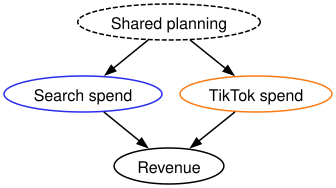

In [2]:
dag = graphviz.Digraph()
dag.attr(rankdir="TB", bgcolor="transparent", size=f"{FIG_WIDTH},{FIG_HEIGHT}")
dag.attr("node", fontname="Helvetica", fontsize="16", penwidth="1.5")
dag.attr("edge", penwidth="1.5")
dag.node("planning", "Shared planning", style="dashed")
dag.node("search", "Search spend", color=to_hex(SEARCH))
dag.node("tiktok", "TikTok spend", color=to_hex(TIKTOK))
dag.node("sales", "Revenue")
dag.edges(
    [
        ("planning", "search"),
        ("planning", "tiktok"),
        ("search", "sales"),
        ("tiktok", "sales"),
    ]
)
display(SVG(dag.pipe(format="svg")))

**Caption:** Causal DAG for the simulation. The dashed planning node drives both measured spends. Each spend affects revenue through its channel response; planning has no additional revenue pathway.

The generator uses the library's own adstock and saturation transformations. Dividing spends by `CHANNEL_SCALE` and revenues by `REVENUE_SCALE` keeps model parameters manageable; multiplying contributions back by `REVENUE_SCALE` recovers dollars. These constants are unit conversions, shared by the generator and fitted model.

In [3]:
def generate_data(seed, n_weeks=80):
    rng = np.random.default_rng(seed)
    planning = np.zeros(n_weeks)

    for t in range(1, n_weeks):
        planning[t] = 0.8 * planning[t - 1] + rng.normal(0, 9)

    spend = 55 + planning[:, None] + rng.normal(0, 1.8, size=(n_weeks, 2))
    X = pd.DataFrame(spend, columns=["search", "tiktok"])
    X.insert(0, "date", pd.date_range("2024-01-01", periods=n_weeks, freq="W-MON"))
    adstock = GeometricAdstock(l_max=4, normalize=True)
    saturation = LogisticSaturation()
    alpha = as_xtensor(np.array([0.3, 0.3]), dims=("channel",))
    lam = as_xtensor(np.array([2.0, 2.0]), dims=("channel",))
    beta = as_xtensor(np.array([0.70, 0.06]), dims=("channel",))
    adstocked = adstock.function(
        x=as_xtensor(spend / CHANNEL_SCALE, dims=("date", "channel")),
        alpha=alpha,
        dim="date",
    )
    responses = (
        saturation.function(x=adstocked, lam=lam, beta=1.0)
        .transpose("date", "channel")
        .values.eval()
    )
    contribution = REVENUE_SCALE * responses * beta.values.eval()
    mean = 700 + contribution.sum(axis=1)
    y = pd.Series(mean + rng.normal(0, 25, n_weeks))
    return X, y, contribution, mean, responses, lam, beta


X, y, true_contribution, true_mean, responses, true_lam, true_beta = generate_data(SEED)
spend = X[["search", "tiktok"]].to_numpy()
true_shares = dict(
    zip(["search", "tiktok"], true_contribution.sum(axis=0) / y.sum(), strict=True)
)
true_shares["paid_media"] = sum(true_shares.values())

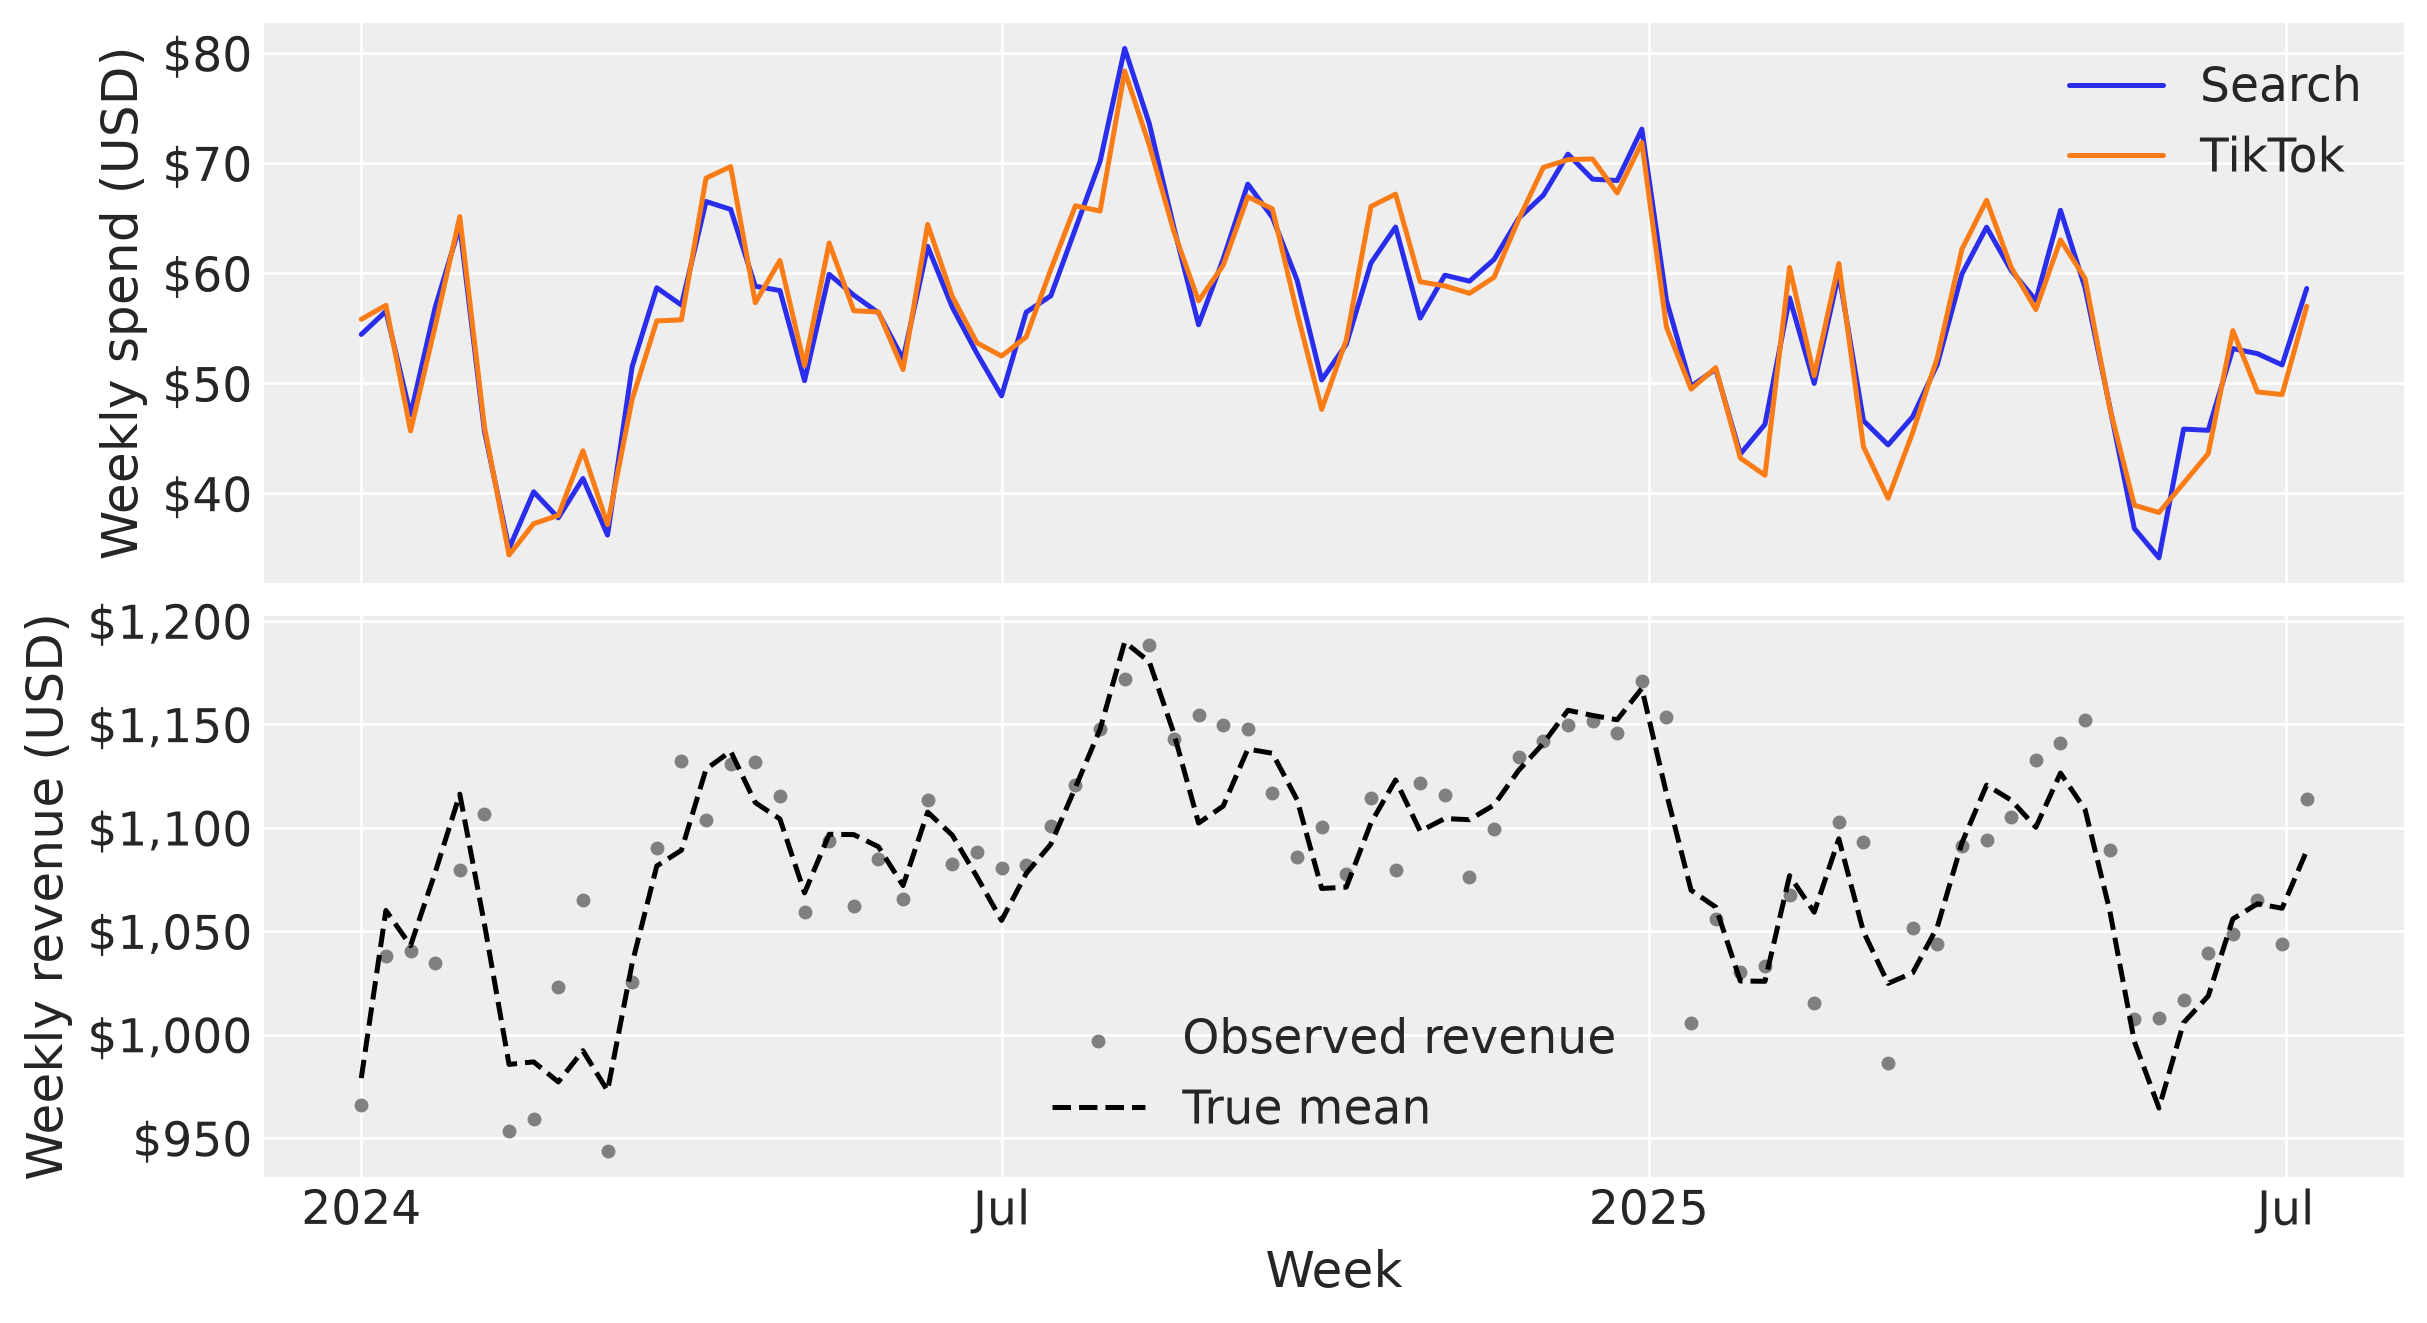

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(FIG_WIDTH, FIG_HEIGHT * 1.5), sharex=True)
for entity in ["search", "tiktok"]:
    axes[0].plot(
        X.date, X[entity], color=ENTITY_COLORS[entity], label=ENTITY_NAMES[entity]
    )
axes[0].set(ylabel="Weekly spend (USD)")
axes[0].legend()
axes[1].scatter(X.date, y, color="0.5", s=10, label="Observed revenue")
axes[1].plot(X.date, true_mean, "k--", label="True mean")
axes[1].set(xlabel="Week", ylabel="Weekly revenue (USD)")
axes[1].legend()
for ax in axes:
    ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
format_dates(axes[1])
plt.show()

**Caption:** Weekly Search and TikTok spend, and simulated revenue with its known conditional mean.

In [5]:
display(
    Markdown(
        f"Spend correlation is {np.corrcoef(spend.T)[0, 1]:.3f}; after adstock and saturation, "
        f"the corresponding response correlation is {np.corrcoef(responses.T)[0, 1]:.3f}. "
        f"Search contributes {true_shares['search']:.1%} of observed revenue and TikTok "
        f"{true_shares['tiktok']:.1%}, for a paid-media total of {true_shares['paid_media']:.1%}."
    )
)

Spend correlation is 0.974; after adstock and saturation, the corresponding response correlation is 0.982. Search contributes 32.5% of observed revenue and TikTok 2.8%, for a paid-media total of 35.3%.

The transformation preserves the channels' similar movements. Many allocations can therefore explain this short revenue series. The next model learns the same adstock, saturation, baseline, and noise structure used to generate the data.

We start with priors allowing substantial variation in media response and a broad baseline. A HalfNormal amplitude with scale 0.5 favors smaller effects while allowing large ones. Later, predictive checks will translate these parameter choices into revenue and ROAS.

In [6]:
def build_mmm():
    mmm = MMM(
        date_column="date",
        channel_columns=["search", "tiktok"],
        adstock=GeometricAdstock(l_max=4, normalize=True),
        saturation=LogisticSaturation(),
        scaling=Scaling(
            target=FixedScaling(dims=(), value=REVENUE_SCALE),
            channel=FixedScaling(dims=(), value=CHANNEL_SCALE),
        ),
        model_config={
            "intercept": Prior("Normal", mu=0.7, sigma=0.2),
            "adstock_alpha": Prior("Beta", alpha=6, beta=14, dims="channel"),
            "saturation_lam": Prior("Gamma", mu=2, sigma=0.6, dims="channel"),
            "saturation_beta": Prior("HalfNormal", sigma=0.5, dims="channel"),
            "likelihood": Prior("Normal", sigma=Prior("HalfNormal", sigma=0.06)),
        },
    )
    mmm.build_model(X, y)
    mmm.add_original_scale_contribution_variable(
        ["channel_contribution", "intercept_contribution"]
    )
    return mmm


SAMPLING = dict(
    draws=1000,
    tune=1500,
    chains=4,
    cores=4,
    target_accept=0.95,
    nuts_sampler="nutpie",
    random_seed=SEED,
    progressbar=False,
)
models = {"Parameter priors only": build_mmm()}

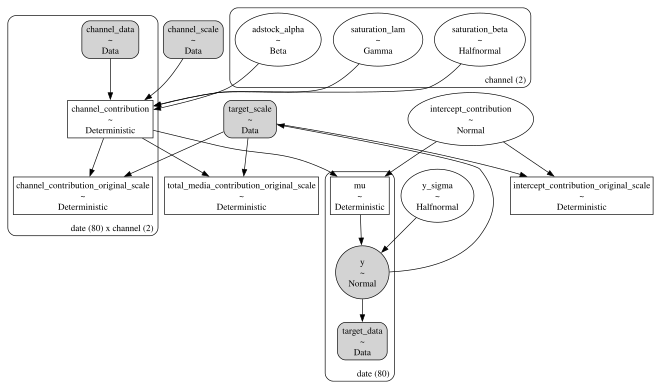

In [7]:
graph = pm.model_to_graphviz(models["Parameter priors only"].model)
graph.attr(size=f"{FIG_WIDTH},{FIG_HEIGHT * 1.5}")
display(SVG(graph.pipe(format="svg")))

**Caption:** PyMC model graph with channel parameters, baseline, observation noise, and the observed revenue node. Original-unit contribution arrays are explicitly registered for this notebook's plots.

In [8]:
models["Parameter priors only"].fit(X, y, **SAMPLING)

NUTS[nutpie]: [intercept_contribution, adstock_alpha, saturation_lam, saturation_beta, y_sigma]


/Users/benjamv/.codex/worktrees/issue-1064/pymc-marketing/.venv/lib/python3.12/site-packages/pymc/sampling/deterministic.py:143: FutureWarning: `merge_dataset` is deprecated and will be removed in a future release. Use `extend_dataset=True` to add the deterministics to the original dataset, passing a `.copy()` of it if it should not be mutated.
  warnings.warn(


<xarray.DataTree>
Group: /
│   Attributes: (12/26)
│       id:                         040a57901c013c6b
│       model_type:                 MMMM (Multi-Dimensional Marketing Mix Model)
│       version:                    0.0.2
│       sampler_config:             {}
│       model_config:               {"intercept": {"dist": "Normal", "kwargs": {"...
│       __serialization_version__:  1
│       ...                         ...
│       contribution_factors:       {"version": 1, "specs": [], "fingerprint": null}
│       dag:                        null
│       treatment_nodes:            null
│       outcome_node:               null
│       mu_effects:                 []
│       cost_per_unit:              null
├── Group: /posterior
│       Dimensions:                                  (chain: 4, draw: 1000, channel: 2,
│                                                     date: 80)
│       Coordinates:
│         * chain                                    (chain) int64 32B 0 1 2 3
│         * draw                                     (draw) int64 8kB 0 1 2 ... 998 999
│         * channel                                  (channel) object 16B 'search' 't...
│         * date                                     (date) datetime64[us] 640B 2024-...
│       Data variables:
│           intercept_contribution                   (chain, draw) float64 32kB 0.749...
│           adstock_alpha                            (chain, draw, channel) float64 64kB ...
│           saturation_lam                           (chain, draw, channel) float64 64kB ...
│           saturation_beta                          (chain, draw, channel) float64 64kB ...
│           y_sigma                                  (chain, draw) float64 32kB 0.026...
│           intercept_contribution_original_scale    (chain, draw) float64 32kB 749.5...
│           channel_contribution_original_scale      (chain, draw, date, channel) float64 5MB ...
│           total_media_contribution_original_scale  (chain, draw) float64 32kB 2.703...
│           mu                                       (chain, draw, date) float64 3MB ...
│           channel_contribution                     (chain, draw, date, channel) float64 5MB ...
│       Attributes:
│           created_at:                 2026-10-20T14:27:16.173537+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.2.0
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
│           inference_library:          nutpie
│           inference_library_version:  0.16.11
│           sampling_time:              4.408060789108276
│           tuning_steps:               1500
│           pymc_marketing_version:     1.2.0
├── Group: /sample_stats
│       Dimensions:                   (chain: 4, draw: 1000)
│       Coordinates:
│         * chain                     (chain) int64 32B 0 1 2 3
│         * draw                      (draw) int64 8kB 0 1 2 3 4 ... 995 996 997 998 999
│       Data variables: (12/20)
│           depth                     (chain, draw) uint64 32kB 7 7 7 7 7 ... 7 7 6 5 7
│           maxdepth_reached          (chain, draw) bool 4kB False False ... False False
│           step_size                 (chain, draw) float64 32kB 0.06995 ... 0.08597
│           transformation_update_id  (chain, draw) int64 32kB 0 0 0 0 0 0 ... 0 0 0 0 0
│           step_size_bar             (chain, draw) float64 32kB 0.07741 ... 0.08625
│           mean_tree_accept          (chain, draw) float64 32kB 0.9162 0.965 ... 0.9816
│           ...                        ...
│           fisher_distance           (chain, draw) float64 32kB 136.9 585.7 ... 190.1
│           transformation_index      (chain, draw) int64 32kB 1273 1273 ... 1272 1272
│           diverging                 (chain, draw) bool 4kB False False ... False False
│           divergence_draw           (chain, draw) uint64 32kB 0 0 0 0 0 ... 0 0 0 0 0
│           divergence_message        (chain, draw) ob

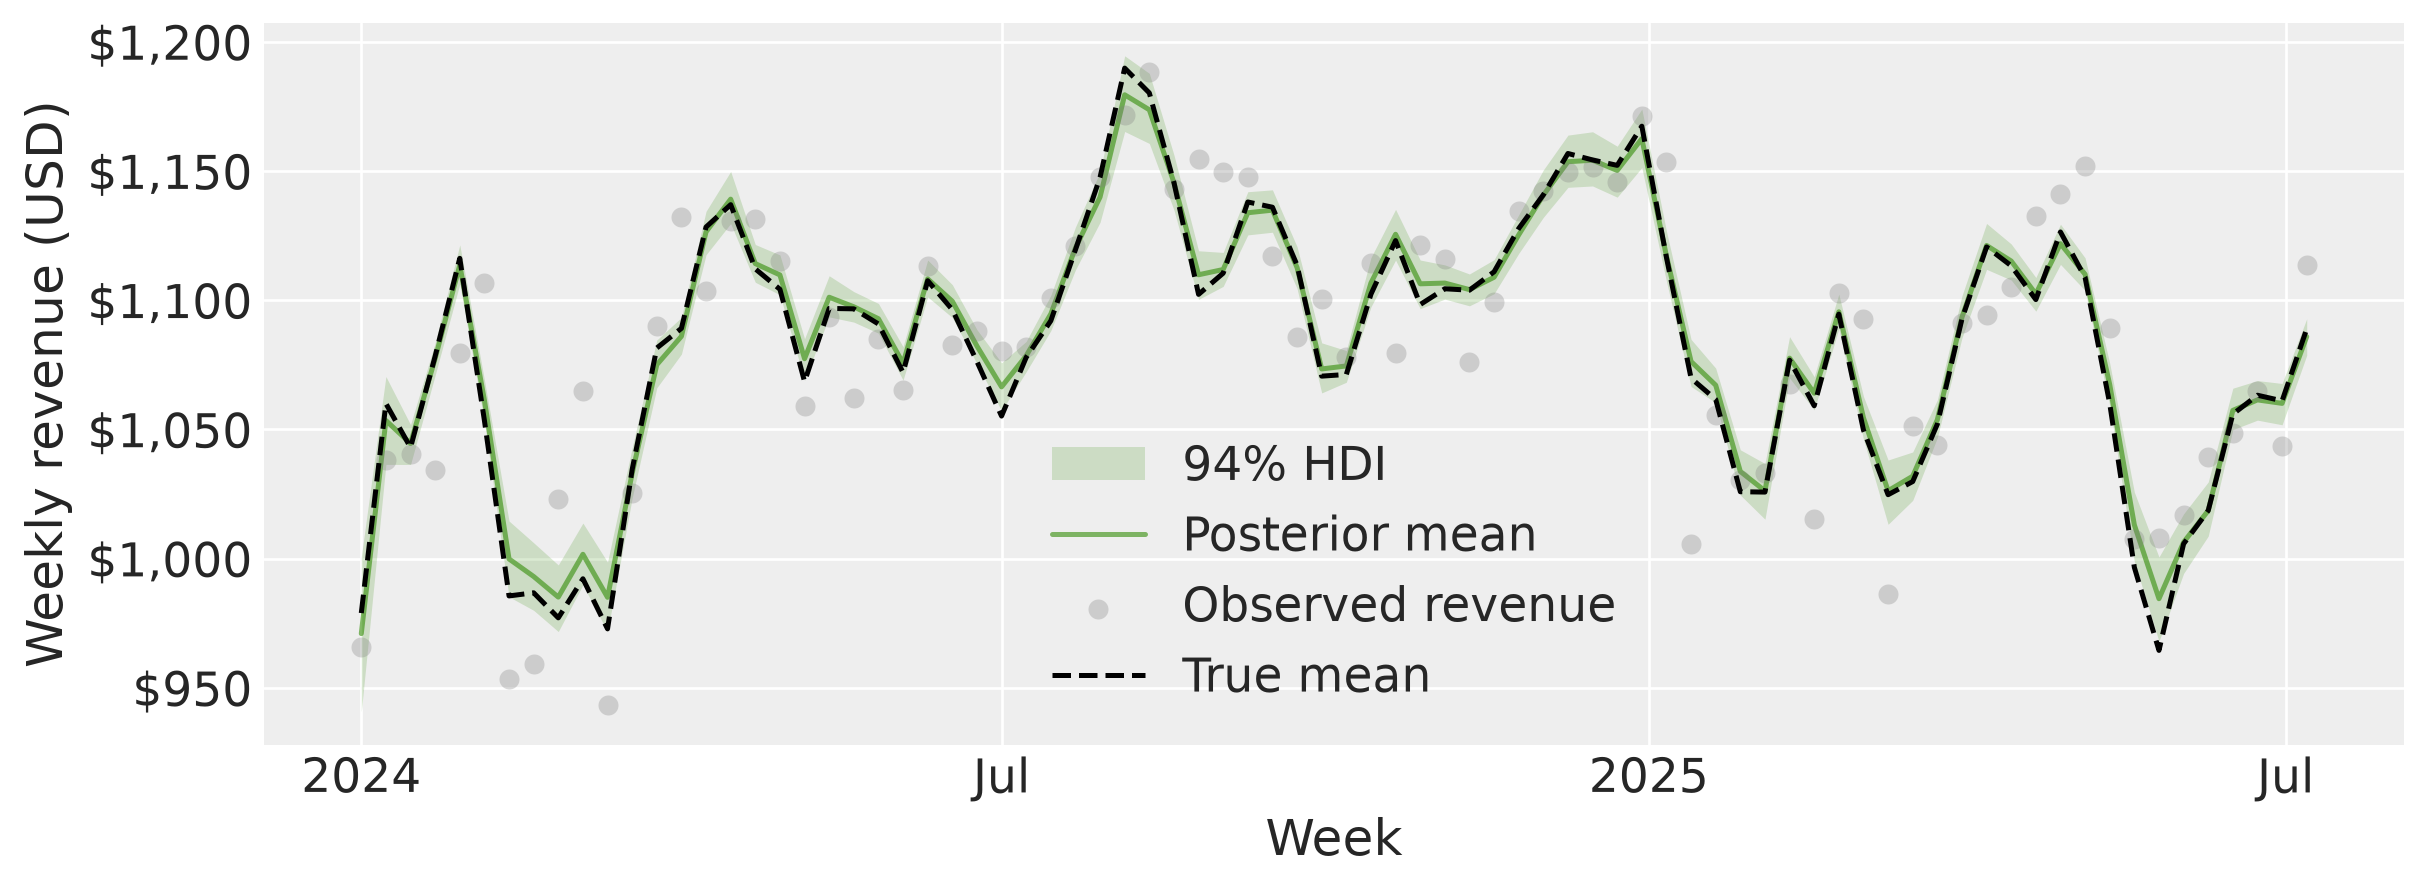

In [9]:
def shares(idata, group="posterior"):
    ds = idata[group]
    channel = ds["channel_contribution_original_scale"].sum("date") / y.sum()
    result = xr.Dataset(
        {
            entity: channel.sel(channel=entity, drop=True)
            for entity in ["search", "tiktok"]
        }
    )
    result["paid_media"] = (
        ds["paid_media_share"] if "paid_media_share" in ds else channel.sum("channel")
    )
    if "tiktok_share" in ds:
        result["tiktok"] = ds["tiktok_share"]
    return result


def mean_revenue(idata, group="posterior"):
    ds = idata[group]
    return (
        ds.intercept_contribution_original_scale
        + ds.channel_contribution_original_scale.sum("channel")
    )


def regression_plot(draws, x, observed, *, color=MEDIA, ylabel="Weekly revenue (USD)"):
    if np.issubdtype(np.asarray(x).dtype, np.datetime64):
        from matplotlib.dates import date2num

        x = date2num(x)
    dim = next(d for d in draws.dims if d not in ("chain", "draw"))
    dt = xr.DataTree.from_dict(
        {
            "posterior_predictive": xr.Dataset({"response": draws}),
            "constant_data": xr.Dataset({"x": (dim, np.asarray(x))}),
            "observed_data": xr.Dataset({"response": (dim, np.asarray(observed))}),
        }
    )
    pc = az.plot_lm(
        dt,
        x="x",
        y="response",
        plot_dim=dim,
        ci_kind="hdi",
        ci_prob=0.94,
        point_estimate="mean",
        smooth=False,
        figure_kwargs={"figsize": (FIG_WIDTH, FIG_HEIGHT)},
        visuals={
            "pe_line": {"color": color, "label": "Posterior mean"},
            "ci_band": {"color": color, "alpha": 0.18, "label": "94% HDI"},
            "observed_scatter": {"color": "0.5", "label": "Observed revenue"},
        },
    )
    ax = pc.viz.ds["figure"].item().get_axes()[0]
    ax.set(xlabel="Week", ylabel=ylabel)
    ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
    return ax


base = models["Parameter priors only"].idata
base_shares = shares(base)
ax = regression_plot(mean_revenue(base), X.date, y)
ax.plot(X.date, true_mean, "k--", label="True mean")
ax.legend()
format_dates(ax)
plt.show()

**Caption:** Posterior mean revenue and 94% HDI for the model with parameter priors only, alongside observed revenue and the true conditional mean.

Revenue prediction averages over many possible parameter combinations. To see whether their channel breakdowns agree, plot the two channel shares jointly.

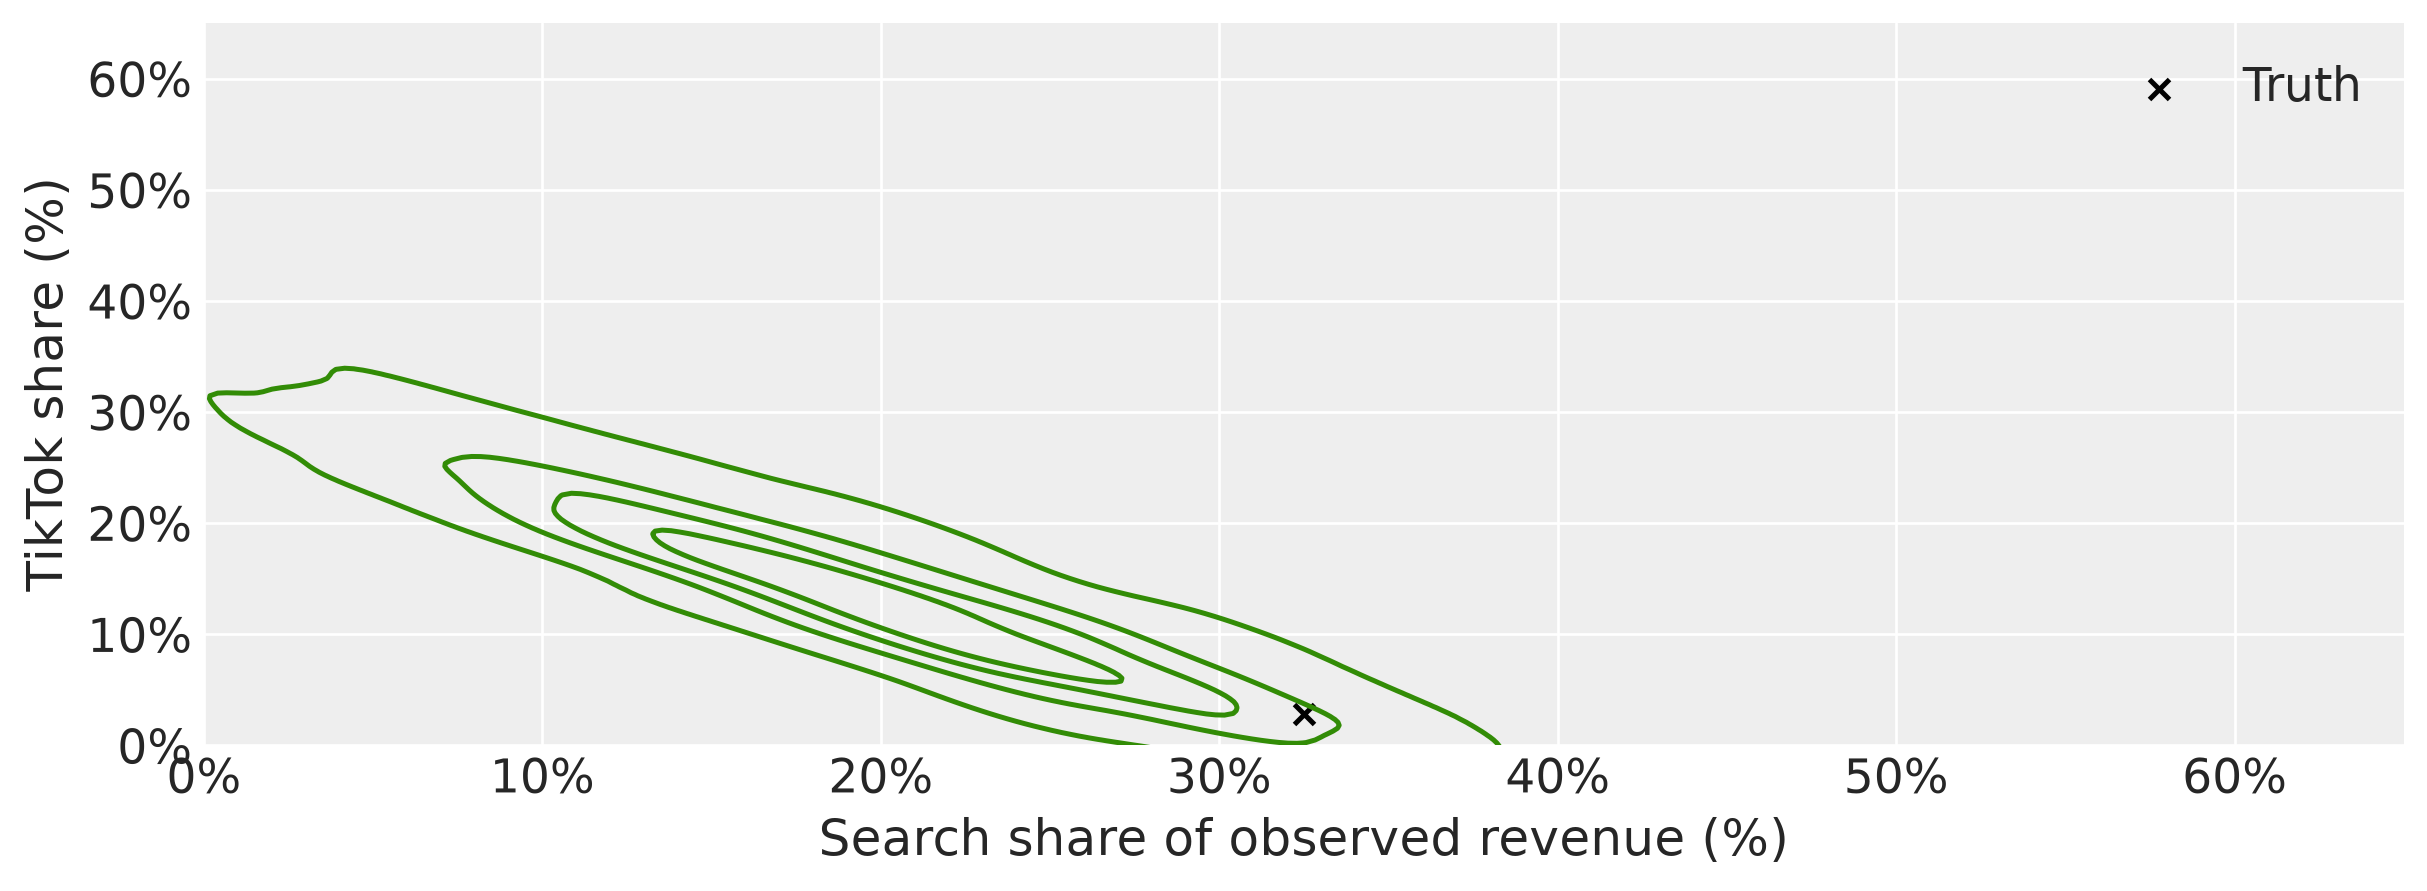

In [10]:
fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT))
sns.kdeplot(
    x=base_shares.search.values.ravel(),
    y=base_shares.tiktok.values.ravel(),
    ax=ax,
    color=MEDIA,
    levels=5,
)
ax.scatter(
    true_shares["search"], true_shares["tiktok"], c="black", marker="x", label="Truth"
)
ax.set(
    xlabel="Search share of observed revenue (%)",
    ylabel="TikTok share (%)",
    xlim=(0, 0.65),
    ylim=(0, 0.65),
)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend()
plt.show()

**Caption:** Joint posterior channel shares; the cross marks the known allocation. Contours summarize the allocation tradeoff.

In [11]:
display(
    Markdown(
        f"The baseline posterior mean assigns {float(base_shares.search.mean()):.1%} to Search "
        f"and {float(base_shares.tiktok.mean()):.1%} to TikTok, compared with truths of "
        f"{true_shares['search']:.1%} and {true_shares['tiktok']:.1%}. "
        "The channel errors and the diagonal tradeoff both matter: "
        "accurate total revenue can coexist with an inaccurate allocation."
    )
)

The baseline posterior mean assigns 19.8% to Search and 13.5% to TikTok, compared with truths of 32.5% and 2.8%. The channel errors and the diagonal tradeoff both matter: accurate total revenue can coexist with an inaccurate allocation.

## Express partial business knowledge

We can add information about historical contributions without choosing a new prior for every adstock or saturation parameter. The entry point is {meth}`~pymc_marketing.mmm.mmm.MMM.add_contribution_factor`: call it on a **built** MMM, after `build_model(X, y)` and before `fit(X, y)`. Our `build_mmm()` helper already builds the graph.

Each call describes one channel or group:

| Argument | Meaning in this example |
|---|---|
| `name` | Name of the aggregate variable saved with the draws, such as `paid_media_share`. |
| `channels` | Channels whose contributions are added together; a one-channel list targets that channel alone. |
| `quantity` | `"share"` divides historical contribution by observed historical revenue. Use `"total"` in this same call for a historical contribution in original revenue units (USD here). |
| `prior` | A scalar `Prior` object whose density weights the selected total or share. This is additional information; the model's parameter priors remain in place. |

Totals pool the selected channels, training dates, and any extra model dimensions. Both numerator and denominator use the cells with finite original outcomes. That aggregation rule is separate from the existing sales likelihood's zero-filling behavior. Shares use a fixed positive observed-revenue total, and can exceed 100%: the model does not force media contributions to sum to observed revenue.

### Define the two business judgments

Suppose the team expects Search and TikTok **together** to contribute 20–40% of historical revenue, with 90% probability in that range. `Prior.constrain` uses PreliZ to choose a **LogNormal** density expressing that judgment.

Separately, the team believes **TikTok alone** is probably a small revenue driver. A **HalfNormal** density with scale 0.025 puts about 95% of its probability below a 5% share. Its density is highest at zero and decreases as the share grows, so this judgment favors smaller values throughout that range; it is more informative than an upper-tail statement alone.

Both densities have nonnegative support. This matches our nonnegative channel contributions and positive revenue denominator. They have no hard upper bound: a rare share above 100% remains possible. A Beta distribution would introduce an additional hard upper bound that this API does not currently support.

In [12]:
paid_media_belief = Prior("LogNormal").constrain(lower=0.20, upper=0.40, mass=0.90)
tiktok_belief = Prior("HalfNormal", sigma=0.025)

/Users/benjamv/.codex/worktrees/issue-1064/pymc-marketing/.venv/lib/python3.12/site-packages/scipy/optimize/_numdiff.py:710: RuntimeWarning: invalid value encountered in subtract
  df = [f_eval - f0 for f_eval in f_evals]


### Build three model comparisons

The labels below are used throughout the remaining figures. Every model has identical parameter priors, data, and sales likelihood; only the added contribution information changes.

| Figure label | Added contribution information | Question it addresses |
|---|---|---|
| **Parameter priors only** | None. Shares are induced by the original adstock and saturation parameter priors. | What allocations does the model allow without the team's judgments? |
| **Paid-media belief** | The LogNormal density on the combined Search + TikTok share. | How much revenue belongs to the two paid channels together? |
| **Paid-media + TikTok beliefs** | The same combined-share density, plus the HalfNormal density on TikTok's share. | How is the paid-media total allocated between the channels? |

The first model was built and fitted above. Build two fresh copies and add their named factors before fitting them:

In [13]:
models["Paid-media belief"] = build_mmm()
models["Paid-media belief"].add_contribution_factor(
    name="paid_media_share",
    channels=["search", "tiktok"],
    quantity="share",
    prior=paid_media_belief,
)
models["Paid-media + TikTok beliefs"] = build_mmm()
models["Paid-media + TikTok beliefs"].add_contribution_factor(
    name="paid_media_share",
    channels=["search", "tiktok"],
    quantity="share",
    prior=paid_media_belief,
)
models["Paid-media + TikTok beliefs"].add_contribution_factor(
    name="tiktok_share",
    channels=["tiktok"],
    quantity="share",
    prior=tiktok_belief,
)

### How the supplied densities combine with the parameter priors

The `prior` argument is the **user-supplied belief density**. For example, `paid_media_belief` supplies a LogNormal density evaluated at the model's combined historical share. It does **not** replace that share's marginal prior distribution.

For a channel group $G$, write its total contribution as $C_G(\theta)$ and its share as $s_G(\theta)$:

$$
C_G(\theta) = \sum_{t,\,c\in G} \mathrm{contribution}_{t,c}(\theta),
\qquad
s_G(\theta) = \frac{C_G(\theta)}{Y},
\qquad Y = \sum_t y_t.
$$

Here the sums cover the observed training cells described above. $Y$ is fixed observed revenue; $\theta$ denotes all model parameters, including adstock, saturation, baseline, and noise parameters. Changing $\theta$ changes the channel contributions and therefore the shares.

With both judgments, the **effective joint prior on those parameters** is

$$
p_{\mathrm{effective}}(\theta)
\propto p_{\mathrm{existing}}(\theta)
\;q_{\mathrm{paid}}\!\left(s_{\mathrm{paid}}(\theta)\right)
\;q_{\mathrm{TikTok}}\!\left(s_{\mathrm{TikTok}}(\theta)\right).
$$

| Symbol | What it means here |
|---|---|
| $p_{\mathrm{existing}}(\theta)$ | Joint density of the original parameter priors specified in `build_mmm()`. |
| $s_{\mathrm{paid}}(\theta)$ | Search + TikTok contribution divided by observed revenue; saved as `paid_media_share`. |
| $s_{\mathrm{TikTok}}(\theta)$ | TikTok contribution divided by observed revenue; saved as `tiktok_share`. |
| $q_{\mathrm{paid}}(s)$ | The user-supplied LogNormal density, from `paid_media_belief`, evaluated at a proposed share $s$. |
| $q_{\mathrm{TikTok}}(s)$ | The user-supplied HalfNormal density, from `tiktok_belief`, evaluated at a proposed share $s$. |
| $\propto$ | Multiply these weights and normalize the resulting joint distribution. |

A parameter combination receives more weight if its historical shares lie where the supplied densities are high. The **Parameter priors only** model has no $q$ terms; the **Paid-media belief** model has only $q_{\mathrm{paid}}$; the third model has both. When fitting, the sales likelihood additionally multiplies this effective joint prior to give the posterior.

The model's original parameter priors and the mapping from parameters to shares also influence the result. Consequently, a supplied density with 90% probability between 20% and 40% need not produce an **effective share distribution** with 90% in that interval. The next plot checks that distinction directly.

```{note}
Support matters. In this example, nonnegative channel-effect priors make the computed shares nonnegative, and the supplied LogNormal and HalfNormal densities respect that support. A real-line density such as Normal is also accepted as a weighting factor; its negative tail does not create negative shares when the model cannot produce them. It should not be described as the share's standalone marginal prior. Signed channel effects require a separate substantive decision about which contribution values are possible.
```

The API supports smooth real-line densities, plus LogNormal and HalfNormal for nonnegative contributions, on additive identity-link MMMs. Finite-support distributions such as Beta and Uniform, truncated distributions, and literal hard caps are unsupported. A nonnegative component must have finite log density at the model's initial historical contribution; an incompatible zero contribution is rejected before registration.

Each factor describes this historical spend period. Predictions and budget changes retain that reference. New fitting periods and time-slice cross-validation require a fresh model with judgments appropriate to each training period. Configure structural effects before adding factors; spend-independent additive effects are supported.

See [`Prior.constrain`](https://www.pymc.io/projects/extras/en/stable/generated/pymc_extras.prior.Prior.constrain.html) for elicitation details.

### Check what the beliefs imply

We first compare the **user-supplied belief density** with the share distributions each complete model actually implies. The black dashed curve in each row is the density passed through `prior=`. The three colored curves are sampled share distributions: parameter priors only, then the paid-media belief added, then both beliefs added. They are different objects, so the dashed curve need not match any colored curve.

{meth}`~pymc_marketing.mmm.mmm.MMM.sample_effective_prior` uses MCMC to combine parameter priors and contribution factors while **excluding the sales likelihood**. The observed revenue total still supplies the fixed denominator and scaling. For the model without contribution factors, it samples only the existing parameter priors.

Ordinary forward prior-predictive sampling ignores Potential factors. The method below includes their effect, returns labeled variables and MCMC diagnostics, and uses the original training data even if prediction has changed the model's mutable inputs.

In [14]:
effective_priors = {
    label: model.sample_effective_prior(**SAMPLING) for label, model in models.items()
}

prior_shares = {
    label: shares(idata, "prior") for label, idata in effective_priors.items()
}

NUTS[nutpie]: [intercept_contribution, adstock_alpha, saturation_lam, saturation_beta, y_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, intercept_contribution, y_sigma]


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, intercept_contribution, y_sigma]


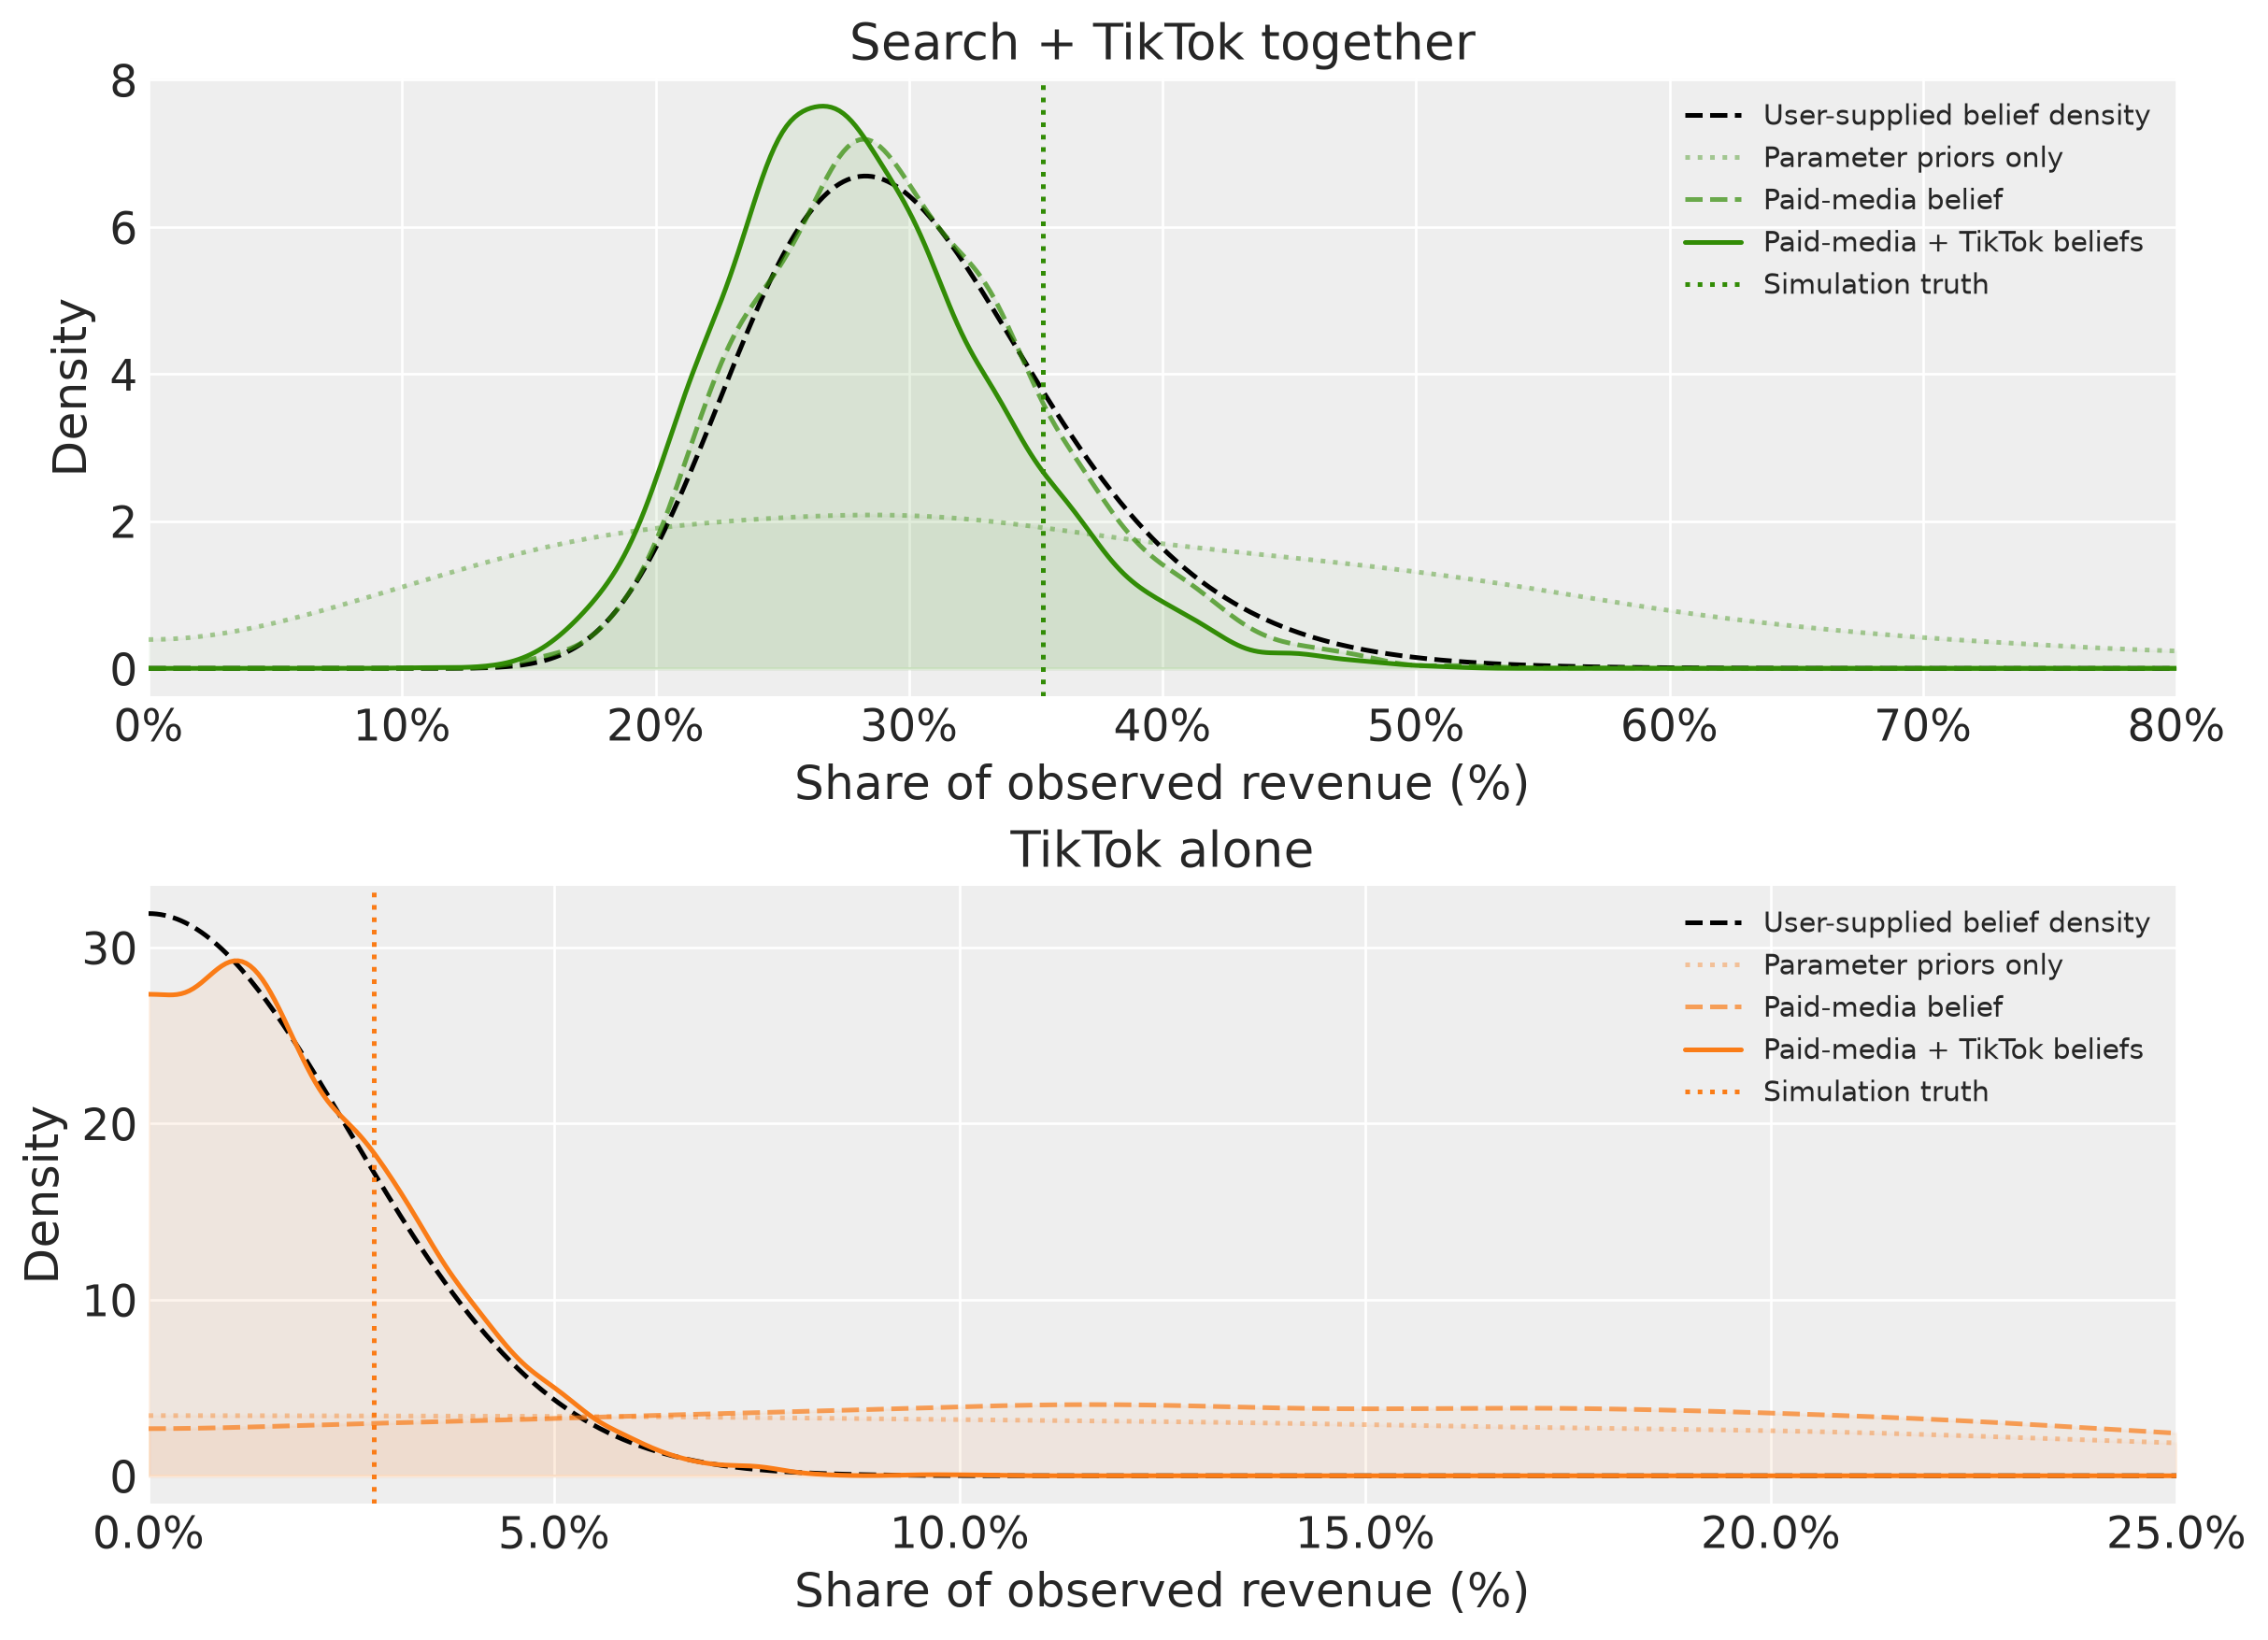

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(FIG_WIDTH, FIG_HEIGHT * 2))
for ax, entity, component, upper in zip(
    axes,
    ["paid_media", "tiktok"],
    [paid_media_belief, tiktok_belief],
    [0.8, 0.25],
    strict=True,
):
    grid = np.linspace(0, upper, 500)
    ax.plot(
        grid, component.preliz.pdf(grid), "k--", label="User-supplied belief density"
    )
    for label in VARIANTS:
        values = prior_shares[label][entity].values.ravel()
        kernel = gaussian_kde(values)
        density = kernel(grid) + kernel(-grid)
        alpha, ls = STYLES[label]
        ax.plot(
            grid,
            density,
            color=ENTITY_COLORS[entity],
            alpha=alpha,
            linestyle=ls,
            label=label,
        )
        ax.fill_between(grid, density, color=ENTITY_COLORS[entity], alpha=0.07 * alpha)
    ax.axvline(
        true_shares[entity],
        color=ENTITY_COLORS[entity],
        linestyle=":",
        label="Simulation truth",
    )
    ax.set(
        title="Search + TikTok together" if entity == "paid_media" else "TikTok alone",
        xlabel="Share of observed revenue (%)",
        ylabel="Density",
        xlim=(0, upper),
    )
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(fontsize=9)
plt.show()

**Caption:** User-supplied share densities (black dashed) and sampled share distributions from the three model comparisons (colored). The top row is the combined paid-media share; the bottom row zooms in on TikTok's share. Colored vertical dotted lines mark truth. Reflection KDE keeps the sampled density curves on nonnegative support.

In the top row, compare **Parameter priors only** with **Paid-media belief** to see how the combined-share judgment changes the model's assumptions before the sales likelihood is used. Comparing the latter with **Paid-media + TikTok beliefs** shows how the additional TikTok judgment can also alter the combined-share distribution.

The bottom row asks a different question: what does each model imply for TikTok alone? A belief on the combined total can change TikTok's distribution even without naming TikTok separately, because the channel effects share that total. The final curve adds the explicit preference for small TikTok contributions. The black dashed curve remains the supplied density, rather than a promise that the final curve will have that shape.

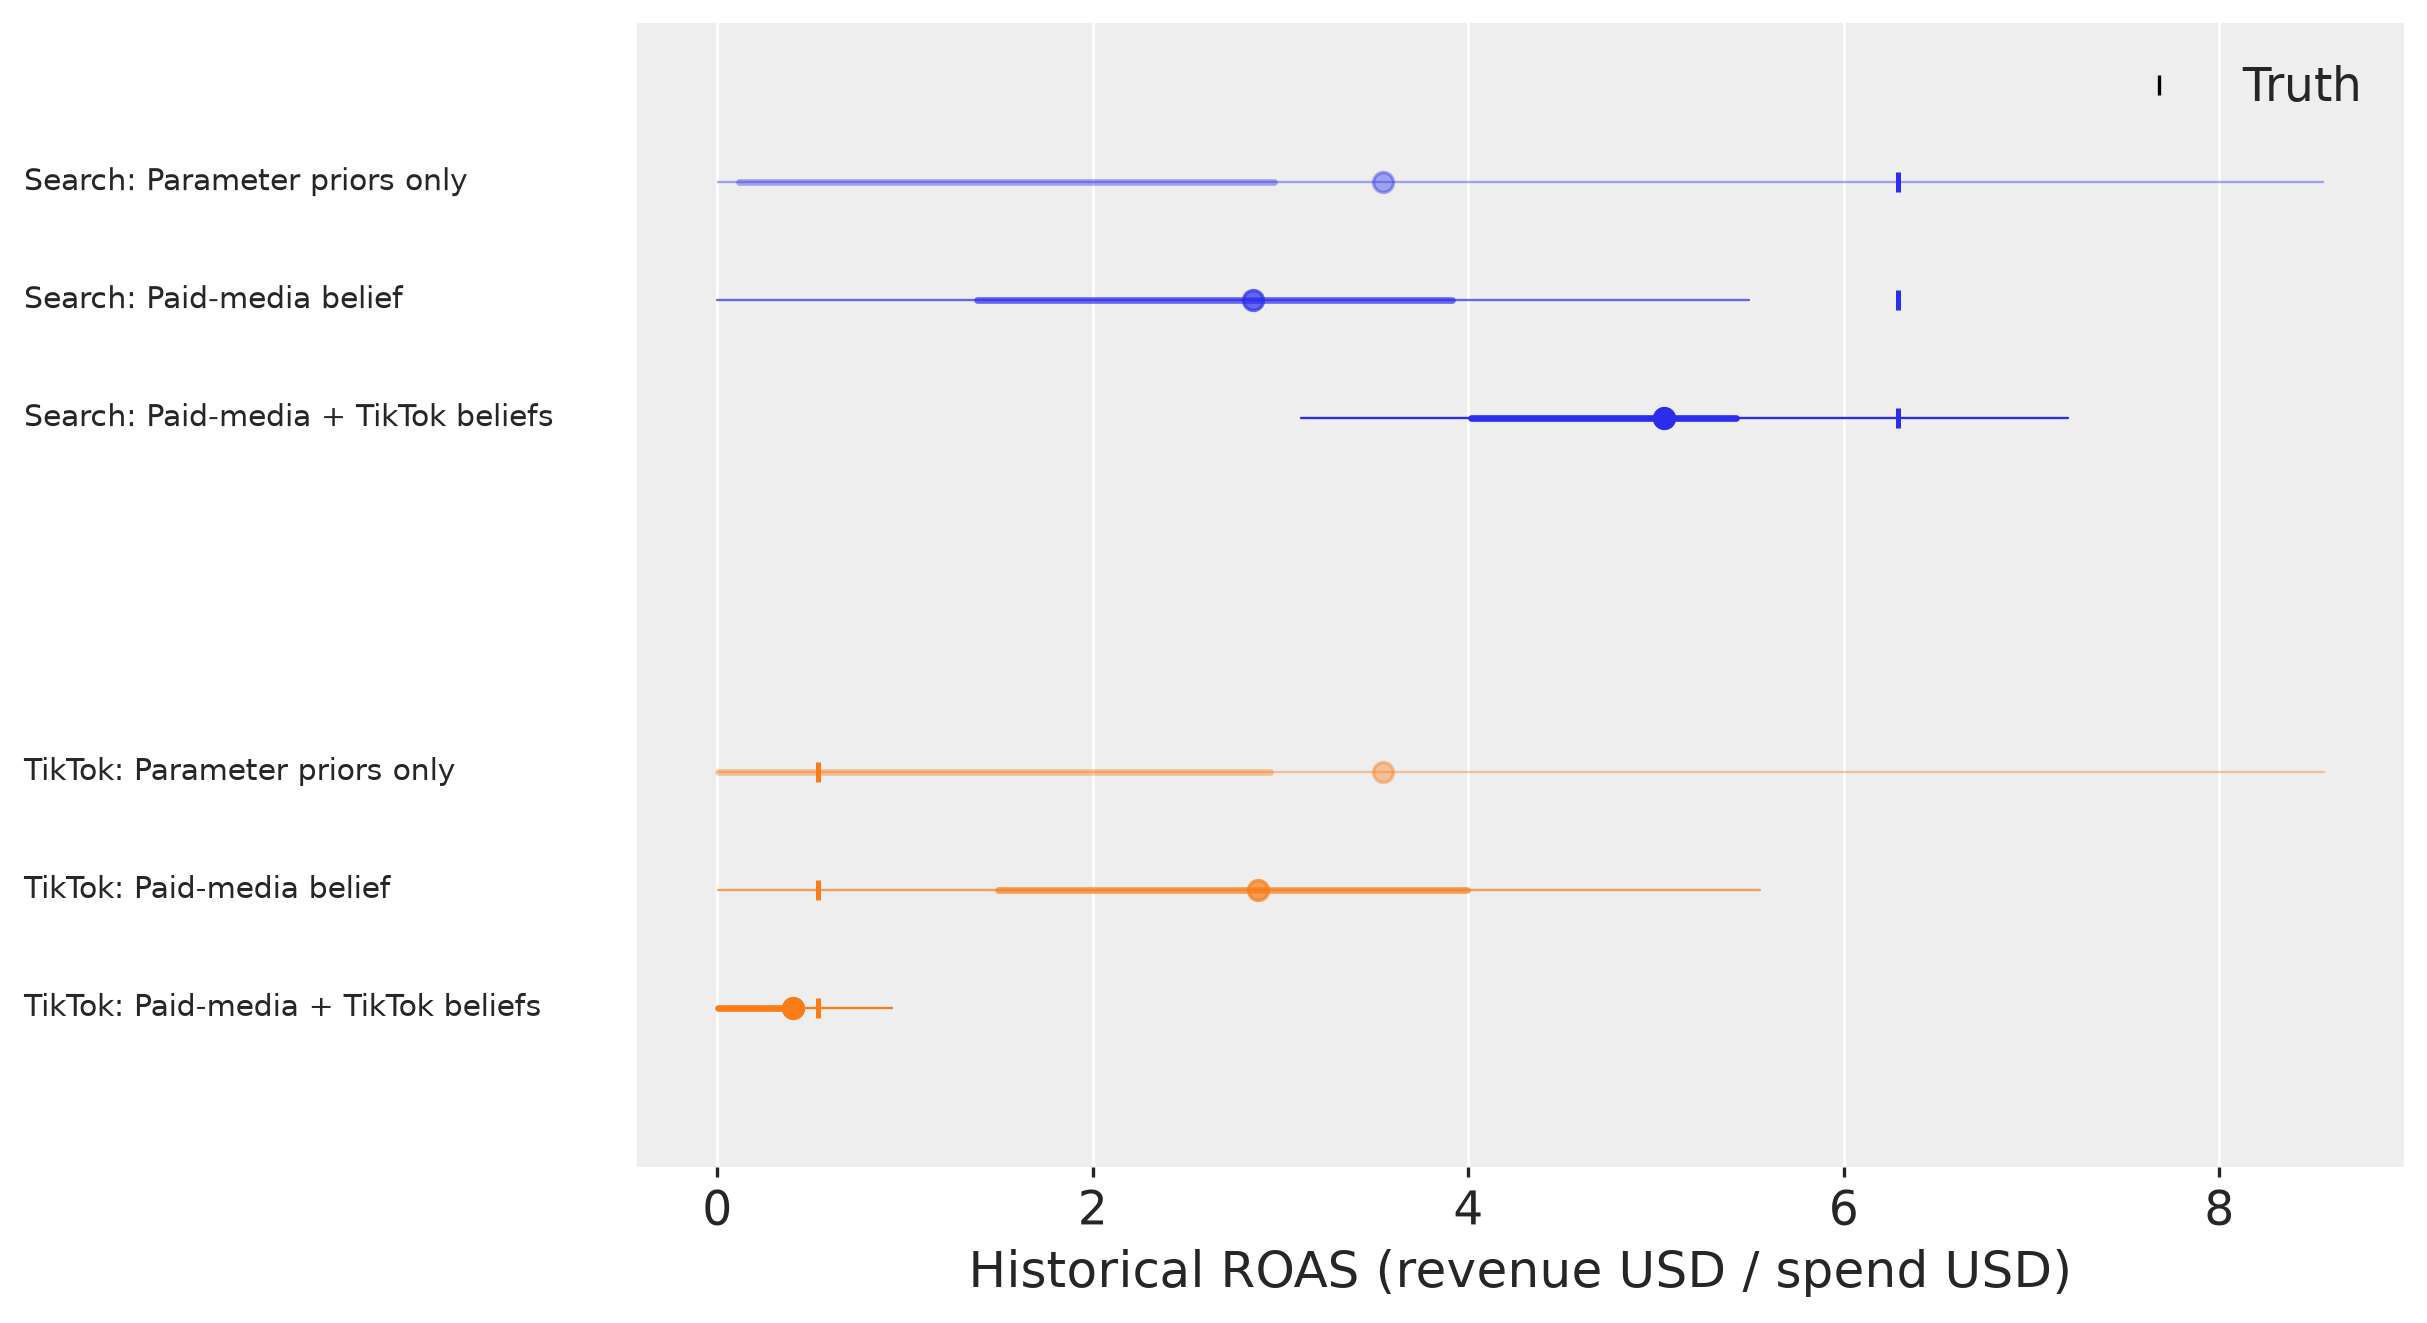

In [16]:
def forest_by_entity(draws_by_variant, truths, xlabel):
    datasets = {
        label: xr.DataTree.from_dict({"posterior": ds})
        for label, ds in draws_by_variant.items()
    }
    pc = az.plot_forest(
        datasets,
        combined=True,
        ci_kind="hdi",
        ci_probs=(0.5, 0.94),
        point_estimate="mean",
        aes={"color": ["__variable__"]},
        figure_kwargs={"figsize": (FIG_WIDTH, FIG_HEIGHT * 1.5)},
    )
    fig = pc.viz.ds["figure"].item()
    ax = pc.viz.ds["plot"].sel(column="forest").item()
    ax.set_xlabel(xlabel)
    label_ax = pc.viz.ds["plot"].sel(column="labels").item()
    for text in list(label_ax.texts):
        text.remove()
    label_ax.set_axis_off()
    lower, upper = ax.get_ylim()
    ax.set_ylim(lower - 0.2, upper + 0.2)
    label_ax.set_ylim(ax.get_ylim())
    if "Share" in xlabel:
        ax.xaxis.set_major_formatter(PercentFormatter(1))
    for entity, truth in truths.items():
        if entity not in pc.viz["point_estimate"]:
            continue
        points = pc.viz["point_estimate"][entity]
        for label in points.coords["model"].values:
            point = points.sel(model=label).item()
            y_pos = point.get_offsets()[0, 1]
            label_ax.text(
                0,
                y_pos,
                f"{ENTITY_NAMES[entity]}: {label}",
                transform=label_ax.get_yaxis_transform(),
                va="center",
                fontsize=9,
            )
            point.set_color(ENTITY_COLORS[entity])
            point.set_alpha(STYLES[str(label)][0])
            for mark in ["trunk", "twig"]:
                line = pc.viz[mark][entity].sel(model=label).item()
                line.set_color(ENTITY_COLORS[entity])
                line.set_alpha(STYLES[str(label)][0])
            ax.scatter(truth, y_pos, marker="|", color=ENTITY_COLORS[entity], zorder=5)
    ax.legend(
        handles=[
            plt.Line2D([], [], color="black", marker="|", linestyle="", label="Truth")
        ]
    )
    return fig


prior_roas = {}
for label, idata in effective_priors.items():
    totals = idata.prior.channel_contribution_original_scale.sum("date")
    prior_roas[label] = xr.Dataset(
        {
            entity: totals.sel(channel=entity, drop=True) / X[entity].sum()
            for entity in ["search", "tiktok"]
        }
    )
true_roas = dict(
    zip(
        ["search", "tiktok"],
        true_contribution.sum(axis=0) / spend.sum(axis=0),
        strict=True,
    )
)
fig = forest_by_entity(
    prior_roas, true_roas, "Historical ROAS (revenue USD / spend USD)"
)
plt.show()

**Caption:** Prior ROAS distributions by channel and model, with posterior-style forest marks denoting means, 50% and 94% HDIs. These are effective-prior draws, before fitting the sales likelihood.

ROAS translates the share assumptions into revenue per dollar spent during this historical period. The TikTok HalfNormal belief favors small returns as well as small shares. Check that this is a judgment your team intends to supply.

Sampling: [y]


Sampling: [y]


Sampling: [y]


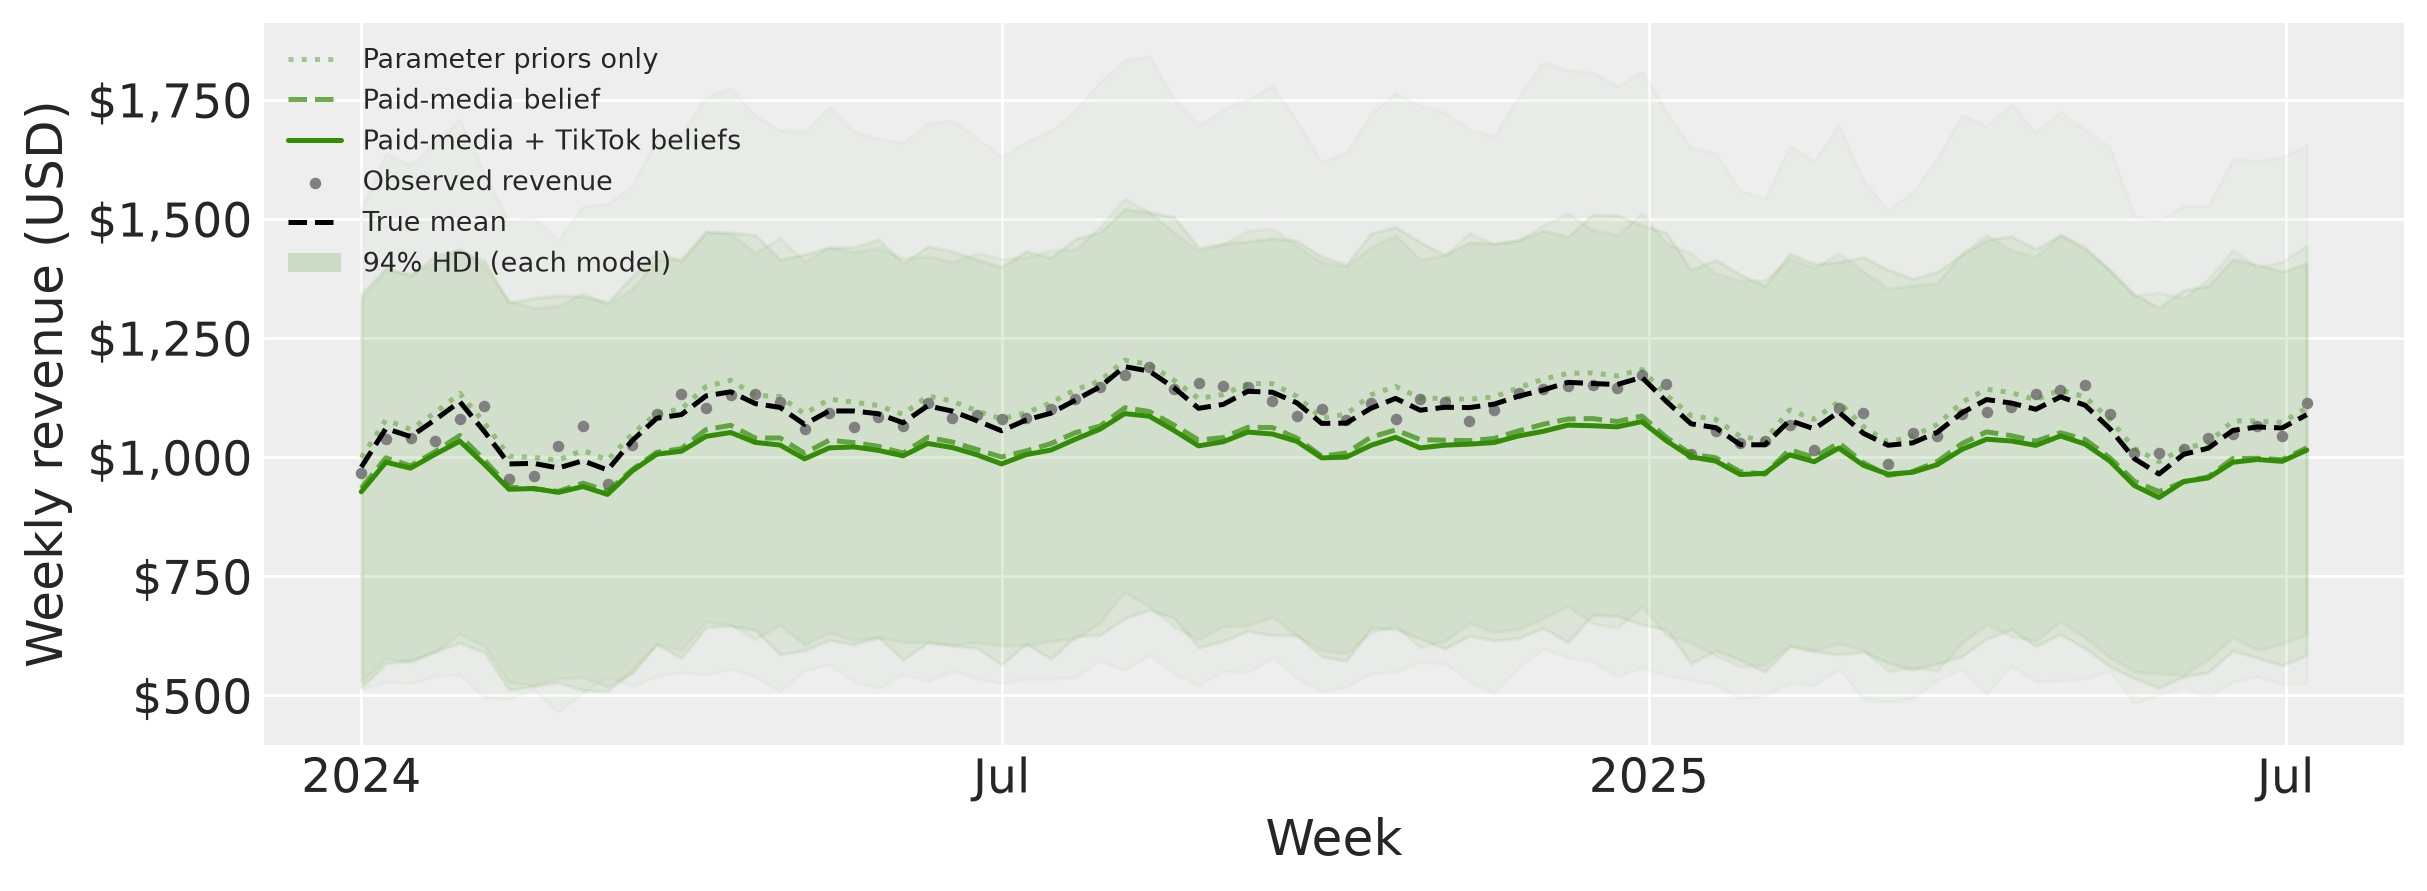

In [17]:
prior_predictions = {}
for label, idata in effective_priors.items():
    with models[label].model, warnings.catch_warnings():
        # The parameter draws already include the factor's effect.
        warnings.filterwarnings(
            "ignore",
            message="The effect of Potentials on other parameters.*",
            category=UserWarning,
        )
        predictive = pm.sample_posterior_predictive(
            idata.prior.dataset,
            var_names=["y"],
            random_seed=SEED,
            progressbar=False,
        )
    prior_predictions[label] = predictive.posterior_predictive.y * REVENUE_SCALE

fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT))
for label in VARIANTS:
    draws = prior_predictions[label]
    bounds = az.hdi(draws, prob=0.94, dim=["chain", "draw"])
    alpha, ls = STYLES[label]
    ax.plot(
        X.date,
        draws.mean(("chain", "draw")),
        color=MEDIA,
        alpha=alpha,
        linestyle=ls,
        label=label,
    )
    ax.fill_between(
        X.date,
        bounds.sel(ci_bound="lower"),
        bounds.sel(ci_bound="upper"),
        color=MEDIA,
        alpha=0.07 * alpha,
    )
ax.scatter(X.date, y, s=6, color="0.5", label="Observed revenue")
ax.plot(X.date, true_mean, "k--", label="True mean")
ax.set(xlabel="Week", ylabel="Weekly revenue (USD)")
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
format_dates(ax)
legend_with_hdi(ax, MEDIA)
plt.show()

**Caption:** Effective-prior predictive mean revenue and 94% HDI, including observation noise. Grey points are observed revenue; black dashed lines mark its known conditional mean. All variants share an axis.

The predictive step retains the effective-prior parameters and draws new observation noise. These trajectories show what the combined assumptions allow. Revenue predictions still include uncertainty about the baseline and observation noise. Supplying a media-share judgment alone does not determine those quantities.

## Update the contribution breakdown

We now fit each model to the same revenue series. The group judgment addresses how much revenue belongs to paid media altogether. The individual judgment addresses how that total is allocated between channels.

In [18]:
for label in ["Paid-media belief", "Paid-media + TikTok beliefs"]:
    models[label].fit(X, y, **SAMPLING)

NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, intercept_contribution, y_sigma]


/Users/benjamv/.codex/worktrees/issue-1064/pymc-marketing/.venv/lib/python3.12/site-packages/pymc/sampling/deterministic.py:143: FutureWarning: `merge_dataset` is deprecated and will be removed in a future release. Use `extend_dataset=True` to add the deterministics to the original dataset, passing a `.copy()` of it if it should not be mutated.
  warnings.warn(


NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, intercept_contribution, y_sigma]


/Users/benjamv/.codex/worktrees/issue-1064/pymc-marketing/.venv/lib/python3.12/site-packages/pymc/sampling/deterministic.py:143: FutureWarning: `merge_dataset` is deprecated and will be removed in a future release. Use `extend_dataset=True` to add the deterministics to the original dataset, passing a `.copy()` of it if it should not be mutated.
  warnings.warn(


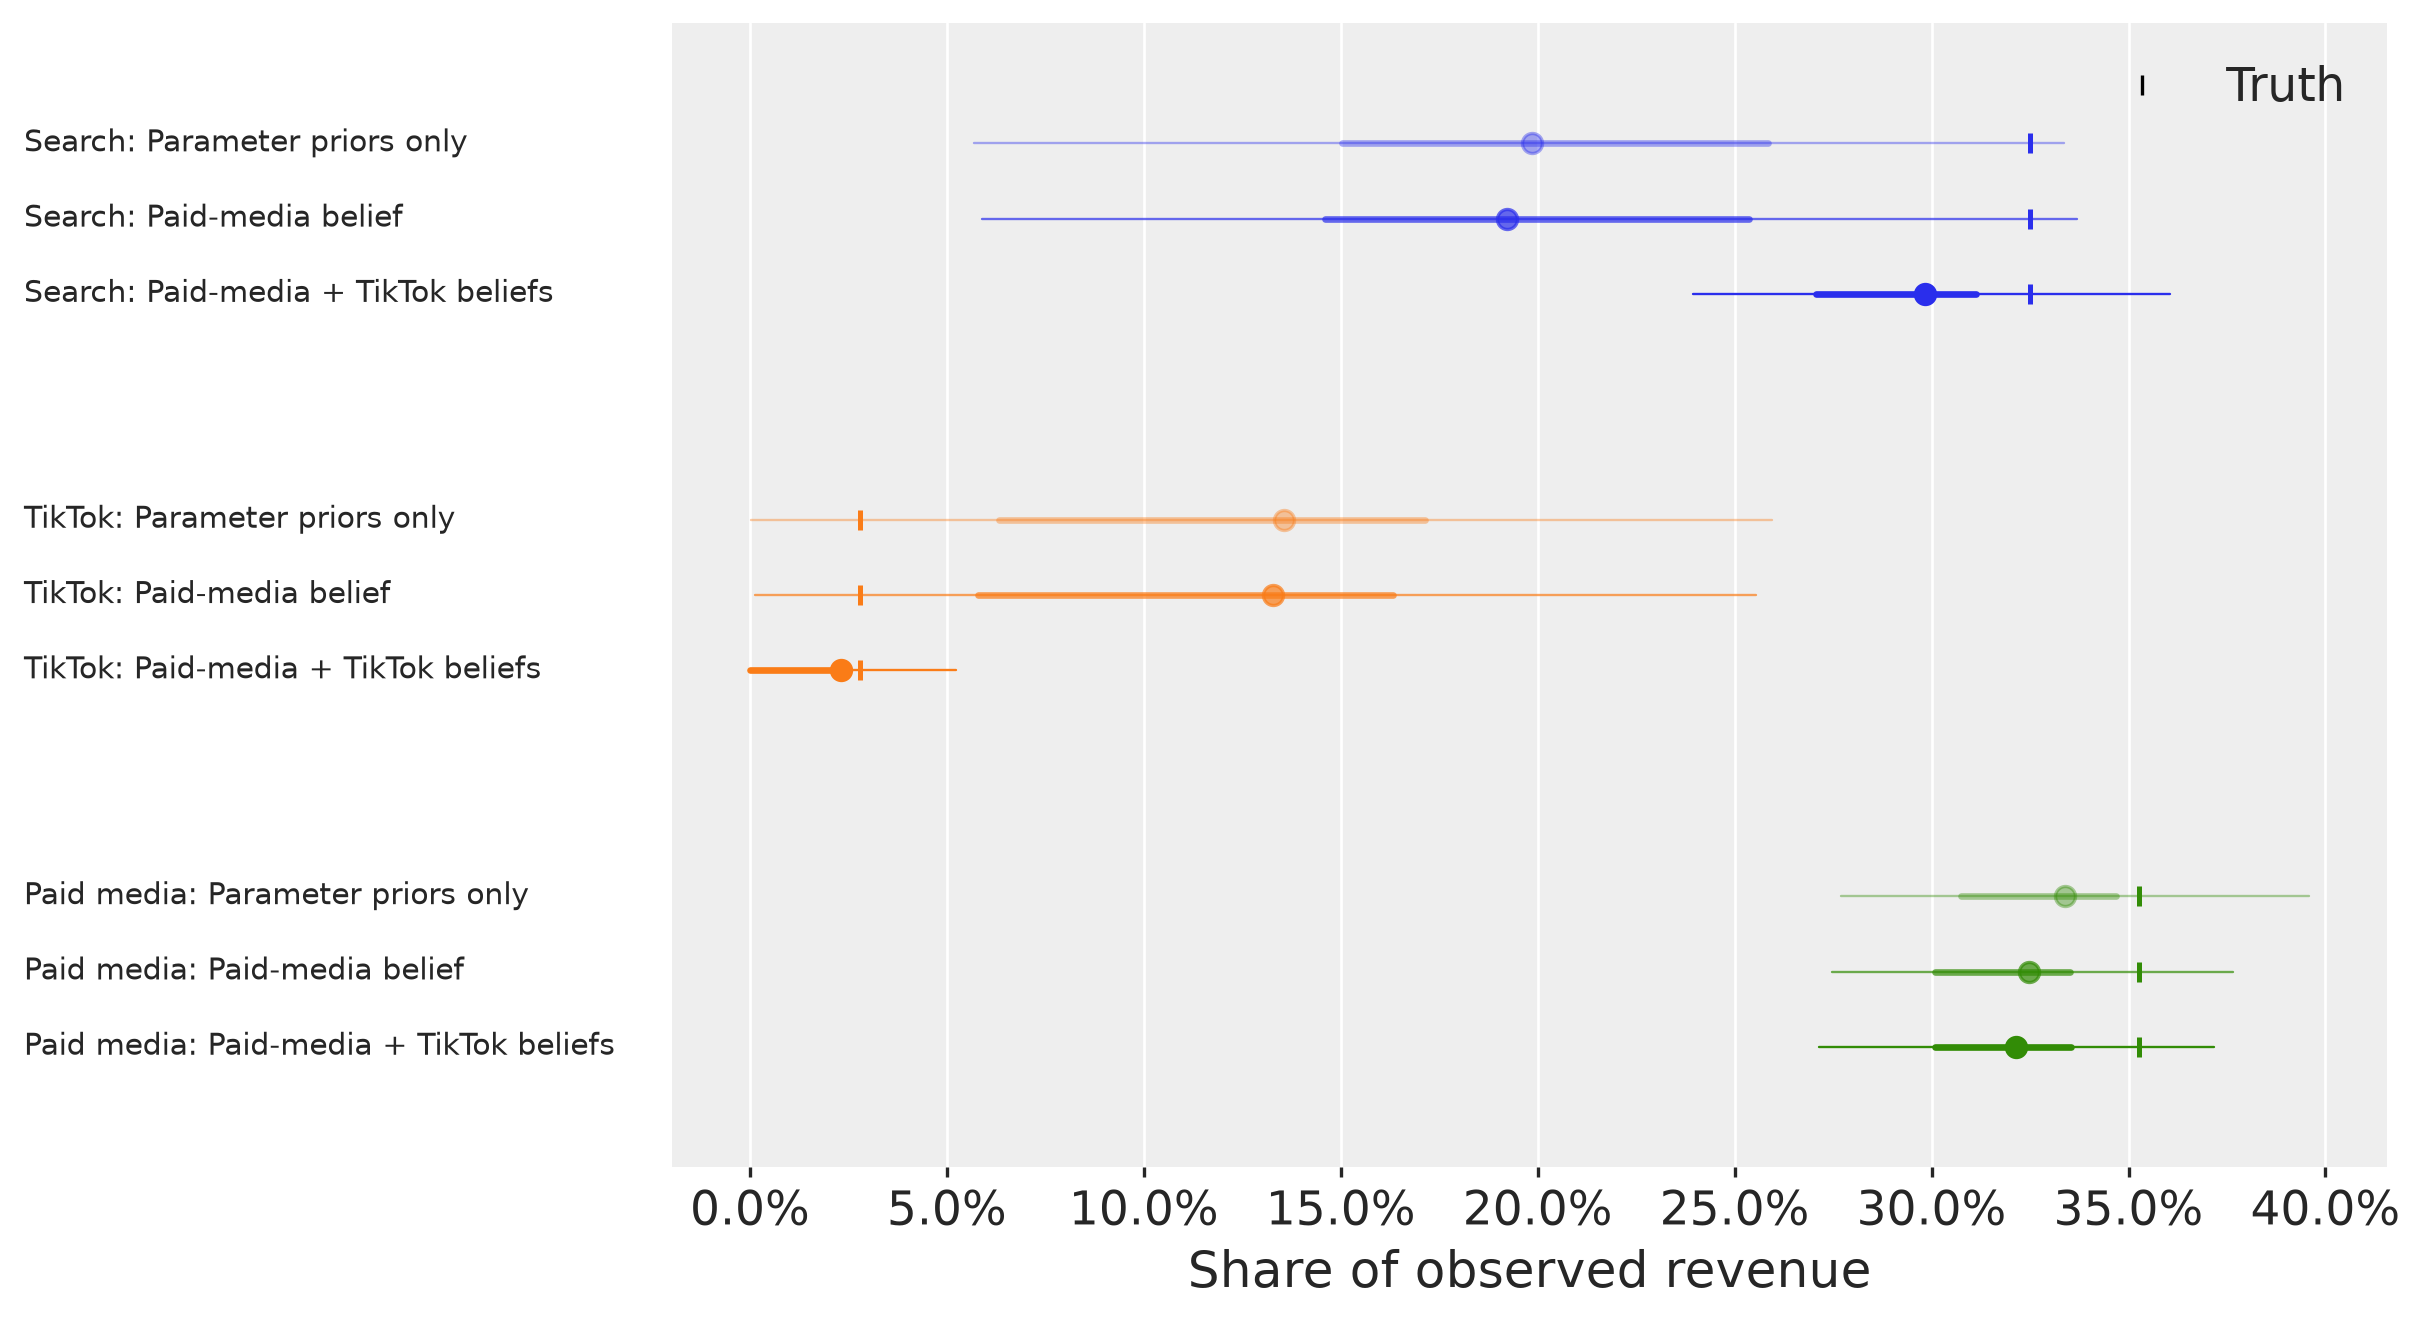

In [19]:
posterior_shares = {label: shares(model.idata) for label, model in models.items()}
fig = forest_by_entity(posterior_shares, true_shares, "Share of observed revenue")
plt.show()

**Caption:** Historical channel and group share posterior means, 50% and 94% HDIs across the three models.

In [20]:
group_means = {
    label: float(ds.paid_media.mean()) for label, ds in posterior_shares.items()
}
prior_tiktok = prior_shares["Paid-media + TikTok beliefs"].tiktok
posterior_tiktok = posterior_shares["Paid-media + TikTok beliefs"].tiktok
prior_bounds = np.asarray(az.hdi(prior_tiktok, prob=0.94, dim=["chain", "draw"]))
posterior_bounds = np.asarray(
    az.hdi(posterior_tiktok, prob=0.94, dim=["chain", "draw"])
)
display(
    Markdown(
        f"The group-share mean moves from {group_means['Parameter priors only']:.1%} "
        f"to {group_means['Paid-media belief']:.1%}, "
        f"against a truth of {true_shares['paid_media']:.1%}. This judgment can move the estimate "
        "away from truth as well as narrow it. "
        f"With both judgments, TikTok's effective-prior mean is {float(prior_tiktok.mean()):.1%} "
        f"and posterior mean is {float(posterior_tiktok.mean()):.1%}, against truth "
        f"{true_shares['tiktok']:.1%}. Compare their intervals too: similarity indicates how much "
        "of the allocation comes from the supplied belief. "
        f"The prior 94% HDI is {prior_bounds[0]:.1%}–{prior_bounds[1]:.1%}; "
        f"the posterior 94% HDI is {posterior_bounds[0]:.1%}–{posterior_bounds[1]:.1%}."
    )
)

The group-share mean moves from 33.4% to 32.5%, against a truth of 35.3%. This judgment can move the estimate away from truth as well as narrow it. With both judgments, TikTok's effective-prior mean is 2.1% and posterior mean is 2.3%, against truth 2.8%. Compare their intervals too: similarity indicates how much of the allocation comes from the supplied belief. The prior 94% HDI is 0.0%–4.8%; the posterior 94% HDI is 0.0%–5.2%.

## Assess the assumptions

What if the team is confidently wrong? Replace the near-zero TikTok judgment with a narrow LogNormal density whose median is an 18% share, while retaining the paid-media judgment, data, and parameter priors. This fourth comparison is labeled **Inaccurate TikTok belief**.

In [21]:
models["Inaccurate TikTok belief"] = build_mmm()
models["Inaccurate TikTok belief"].add_contribution_factor(
    "paid_media_share",
    ["search", "tiktok"],
    "share",
    paid_media_belief,
)
models["Inaccurate TikTok belief"].add_contribution_factor(
    "tiktok_share",
    ["tiktok"],
    "share",
    Prior("LogNormal", mu=np.log(0.18), sigma=0.06),
)
models["Inaccurate TikTok belief"].fit(X, y, **SAMPLING)
posterior_shares["Inaccurate TikTok belief"] = shares(
    models["Inaccurate TikTok belief"].idata
)

NUTS[nutpie]: [adstock_alpha, saturation_lam, saturation_beta, intercept_contribution, y_sigma]


/Users/benjamv/.codex/worktrees/issue-1064/pymc-marketing/.venv/lib/python3.12/site-packages/pymc/sampling/deterministic.py:143: FutureWarning: `merge_dataset` is deprecated and will be removed in a future release. Use `extend_dataset=True` to add the deterministics to the original dataset, passing a `.copy()` of it if it should not be mutated.
  warnings.warn(


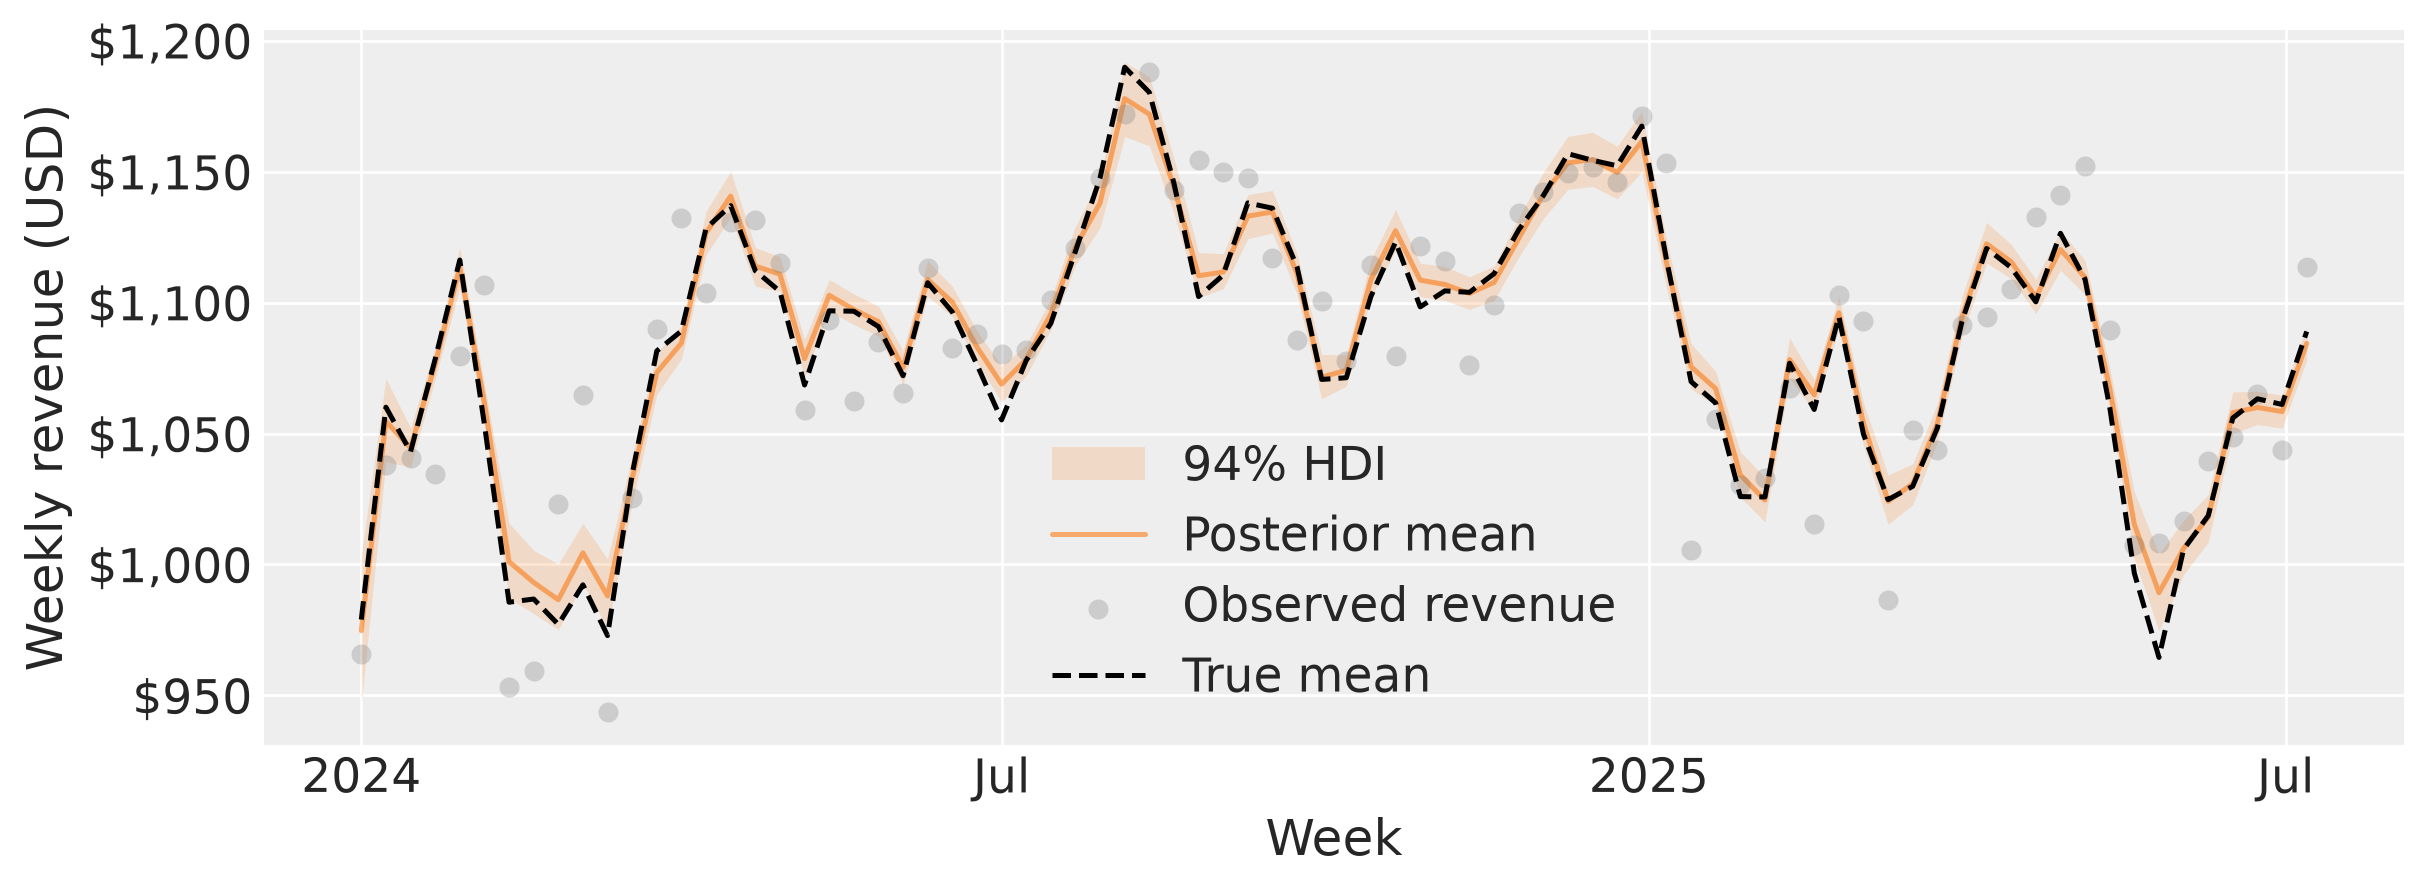

In [22]:
ax = regression_plot(
    mean_revenue(models["Inaccurate TikTok belief"].idata), X.date, y, color=TIKTOK
)
ax.plot(X.date, true_mean, "k--", label="True mean")
ax.legend()
format_dates(ax)
plt.show()

**Caption:** Revenue mean and 94% HDI under the inaccurate TikTok factor, with observations and the true conditional mean.

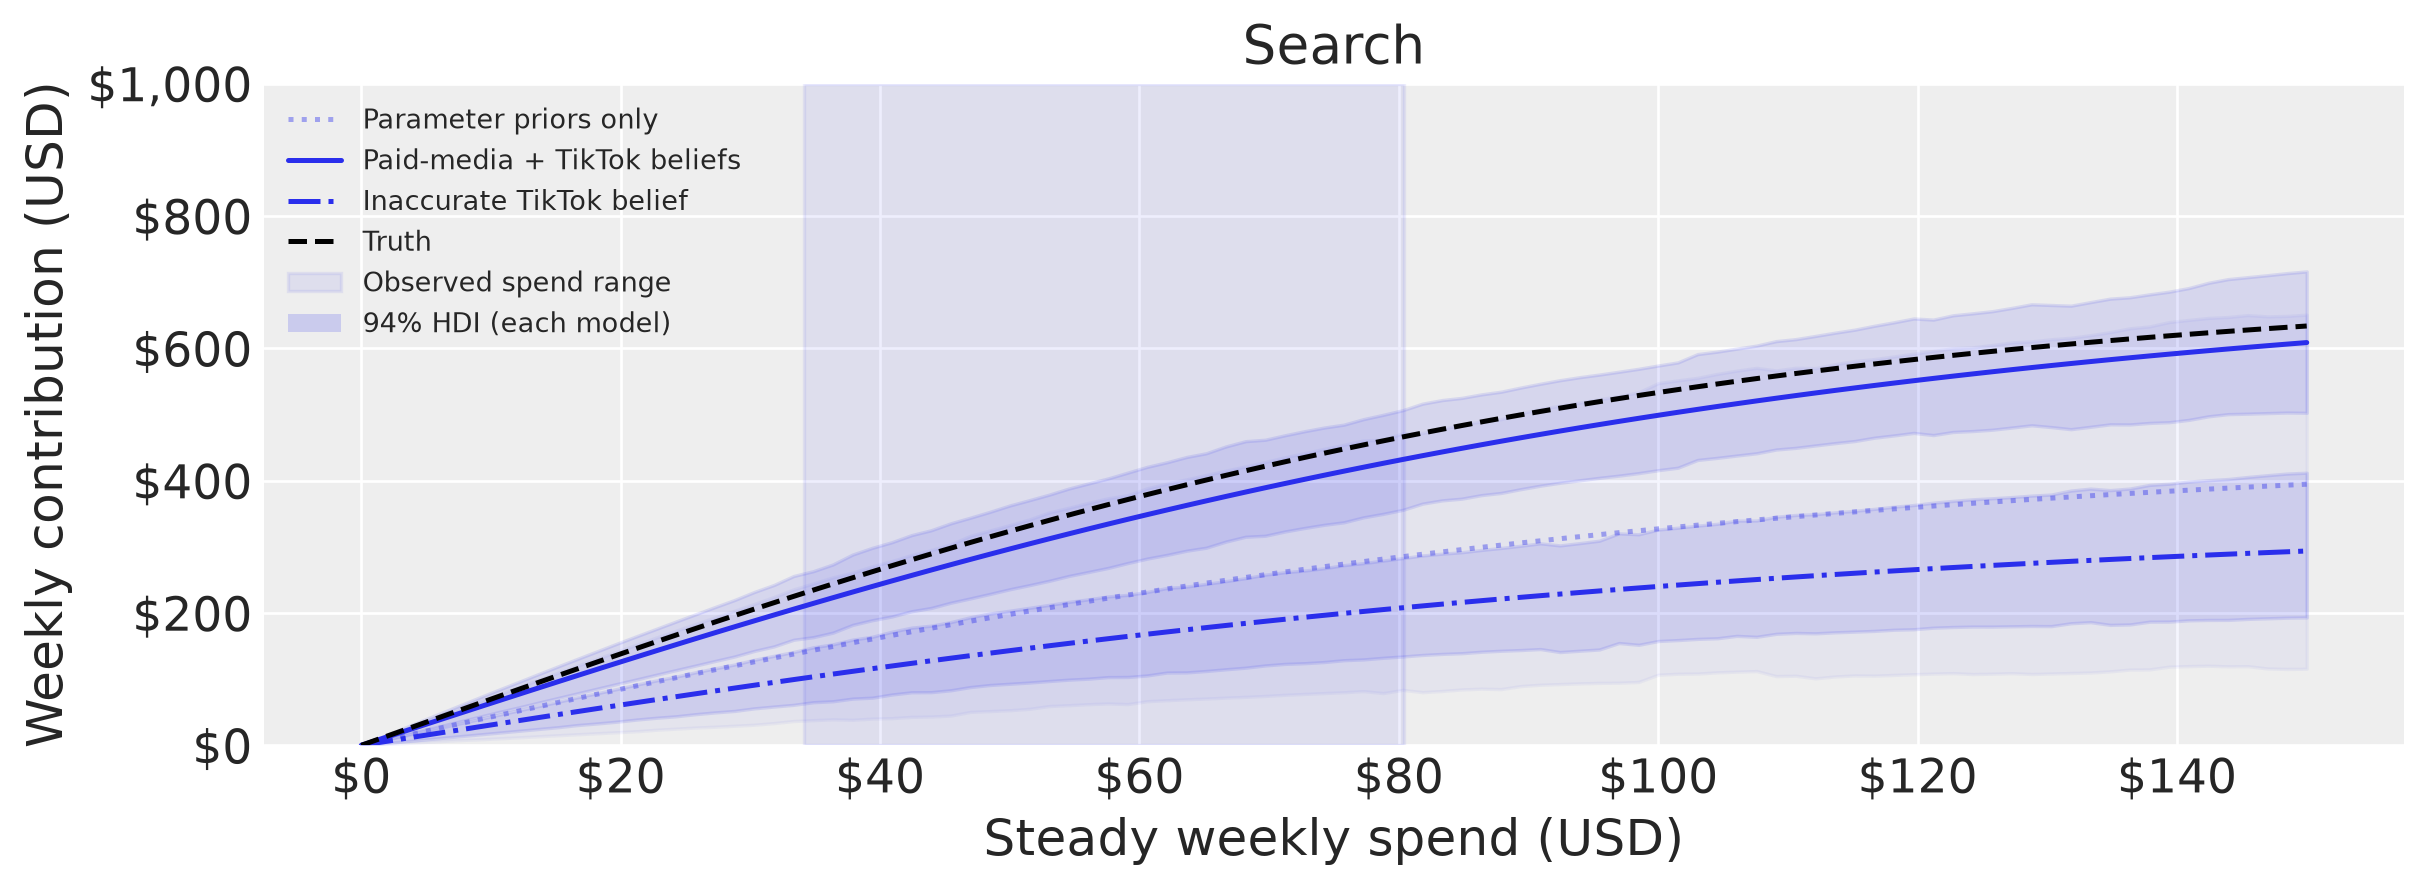

In [23]:
spend_grid = np.linspace(0, 150, 100)
fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT))
for label in [
    "Parameter priors only",
    "Paid-media + TikTok beliefs",
    "Inaccurate TikTok belief",
]:
    posterior = models[label].idata.posterior
    curves = (
        (
            REVENUE_SCALE
            * LogisticSaturation().function(
                x=as_xtensor(spend_grid / CHANNEL_SCALE, dims=("spend",)),
                lam=as_xtensor(posterior.saturation_lam),
                beta=as_xtensor(posterior.saturation_beta),
            )
        )
        .transpose("chain", "draw", "spend", "channel")
        .values.eval()[..., 0]
    )
    draws = xr.DataArray(curves, dims=("chain", "draw", "spend"))
    bounds = az.hdi(draws, prob=0.94, dim=["chain", "draw"])
    alpha, ls = STYLES[label]
    ax.plot(
        spend_grid,
        draws.mean(("chain", "draw")),
        color=ENTITY_COLORS["search"],
        alpha=alpha,
        linestyle=ls,
        label=label,
    )
    ax.fill_between(
        spend_grid,
        bounds.sel(ci_bound="lower"),
        bounds.sel(ci_bound="upper"),
        color=ENTITY_COLORS["search"],
        alpha=0.12 * alpha,
    )
truth = (
    (
        REVENUE_SCALE
        * LogisticSaturation().function(
            x=as_xtensor(spend_grid / CHANNEL_SCALE, dims=("spend",)),
            lam=true_lam,
            beta=true_beta,
        )
    )
    .transpose("spend", "channel")
    .values.eval()[:, 0]
)
ax.plot(spend_grid, truth, "k--", label="Truth")
ax.axvspan(
    spend[:, 0].min(),
    spend[:, 0].max(),
    color=ENTITY_COLORS["search"],
    alpha=0.08,
    label="Observed spend range",
)
ax.set(
    title=ENTITY_NAMES["search"],
    xlabel="Steady weekly spend (USD)",
    ylabel="Weekly contribution (USD)",
    ylim=(0, 1000),
)
ax.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
legend_with_hdi(ax, ENTITY_COLORS["search"])
plt.show()

**Caption:** Search steady-spend response posterior means and 94% HDIs, with the true curve and shaded observed spend range.

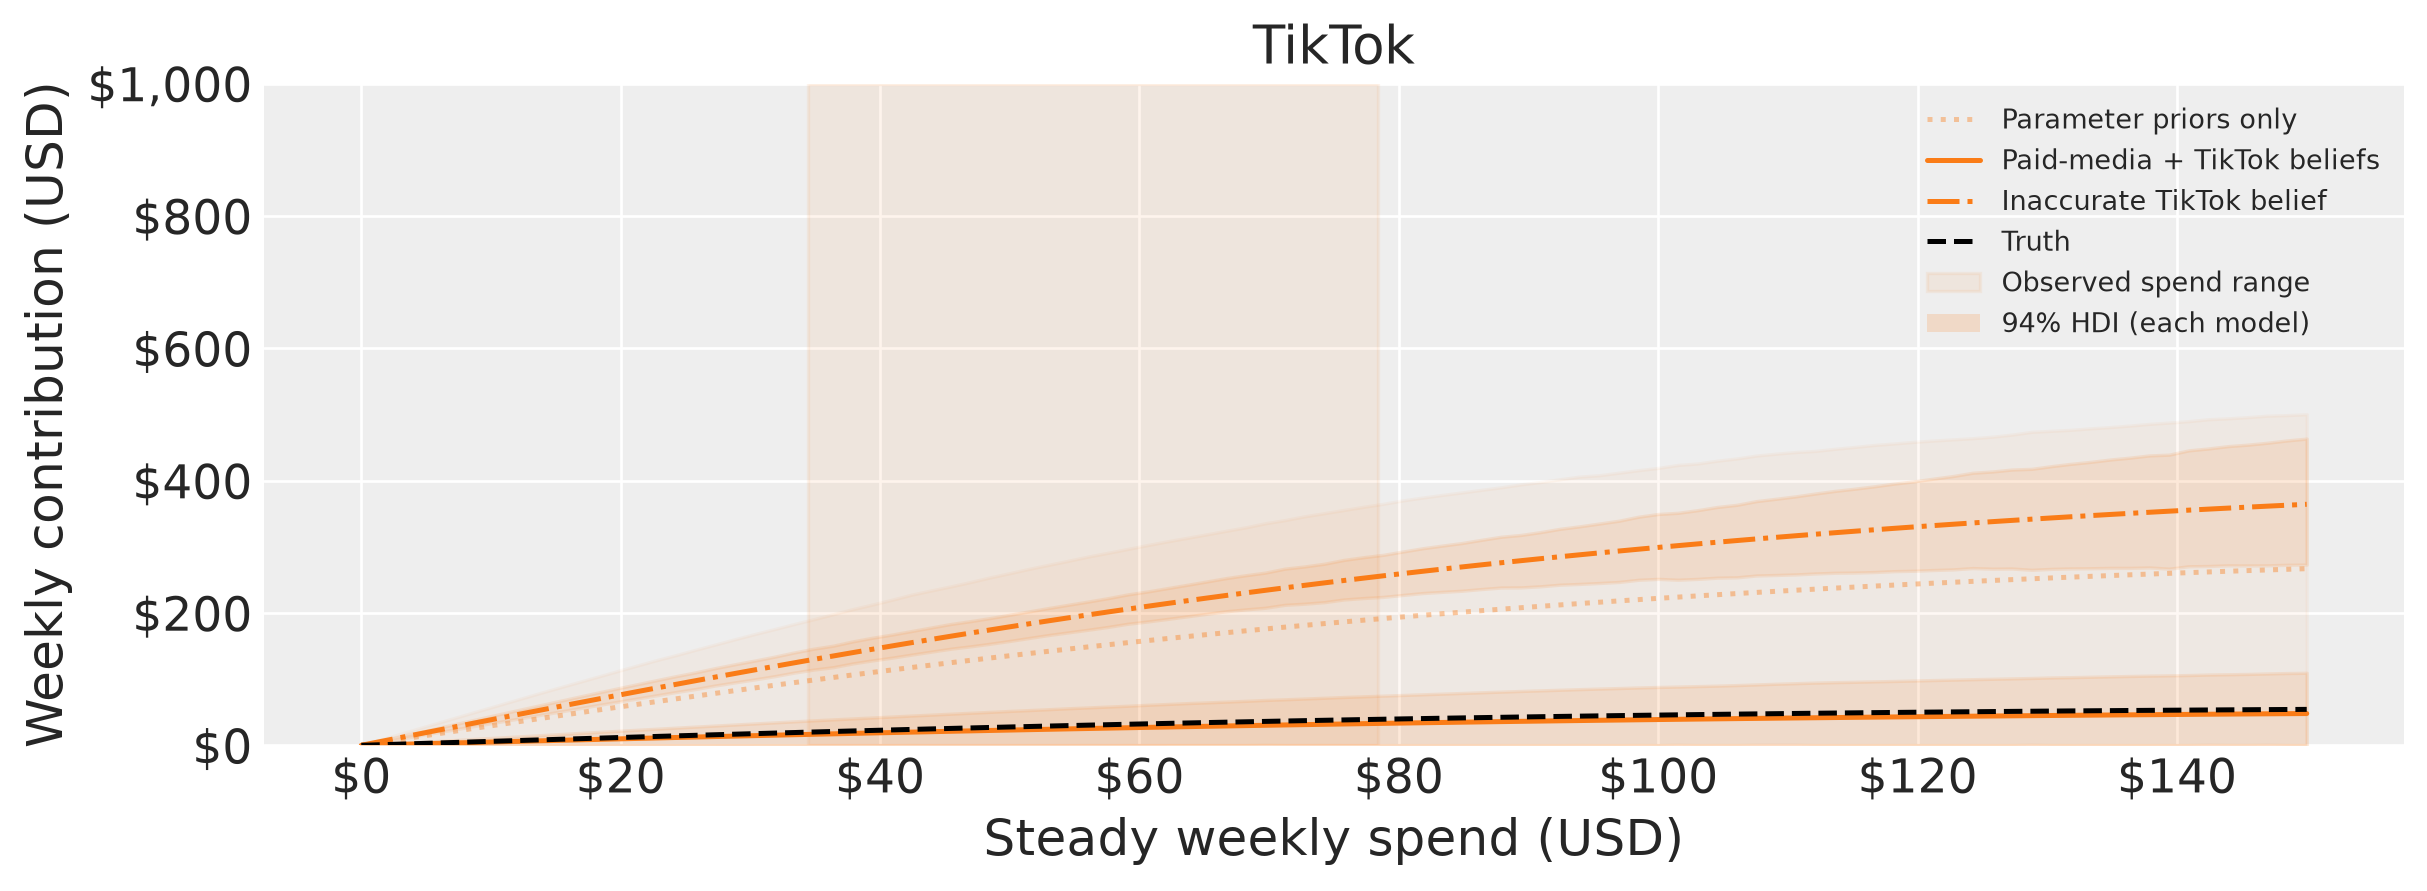

In [24]:
spend_grid = np.linspace(0, 150, 100)
fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT))
for label in [
    "Parameter priors only",
    "Paid-media + TikTok beliefs",
    "Inaccurate TikTok belief",
]:
    posterior = models[label].idata.posterior
    curves = (
        (
            REVENUE_SCALE
            * LogisticSaturation().function(
                x=as_xtensor(spend_grid / CHANNEL_SCALE, dims=("spend",)),
                lam=as_xtensor(posterior.saturation_lam),
                beta=as_xtensor(posterior.saturation_beta),
            )
        )
        .transpose("chain", "draw", "spend", "channel")
        .values.eval()[..., 1]
    )
    draws = xr.DataArray(curves, dims=("chain", "draw", "spend"))
    bounds = az.hdi(draws, prob=0.94, dim=["chain", "draw"])
    alpha, ls = STYLES[label]
    ax.plot(
        spend_grid,
        draws.mean(("chain", "draw")),
        color=ENTITY_COLORS["tiktok"],
        alpha=alpha,
        linestyle=ls,
        label=label,
    )
    ax.fill_between(
        spend_grid,
        bounds.sel(ci_bound="lower"),
        bounds.sel(ci_bound="upper"),
        color=ENTITY_COLORS["tiktok"],
        alpha=0.12 * alpha,
    )
truth = (
    (
        REVENUE_SCALE
        * LogisticSaturation().function(
            x=as_xtensor(spend_grid / CHANNEL_SCALE, dims=("spend",)),
            lam=true_lam,
            beta=true_beta,
        )
    )
    .transpose("spend", "channel")
    .values.eval()[:, 1]
)
ax.plot(spend_grid, truth, "k--", label="Truth")
ax.axvspan(
    spend[:, 1].min(),
    spend[:, 1].max(),
    color=ENTITY_COLORS["tiktok"],
    alpha=0.08,
    label="Observed spend range",
)
ax.set(
    title=ENTITY_NAMES["tiktok"],
    xlabel="Steady weekly spend (USD)",
    ylabel="Weekly contribution (USD)",
    ylim=(0, 1000),
)
ax.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
legend_with_hdi(ax, ENTITY_COLORS["tiktok"])
plt.show()

**Caption:** TikTok steady-spend response posterior means and 94% HDIs, with the true curve and shaded observed spend range.

Historical totals summarize responses over the spends we observed. Response curves extend that question to other spend levels, where shape uncertainty can remain substantial. The inaccurate belief can change channel responses while leaving the combined revenue trajectory plausible.

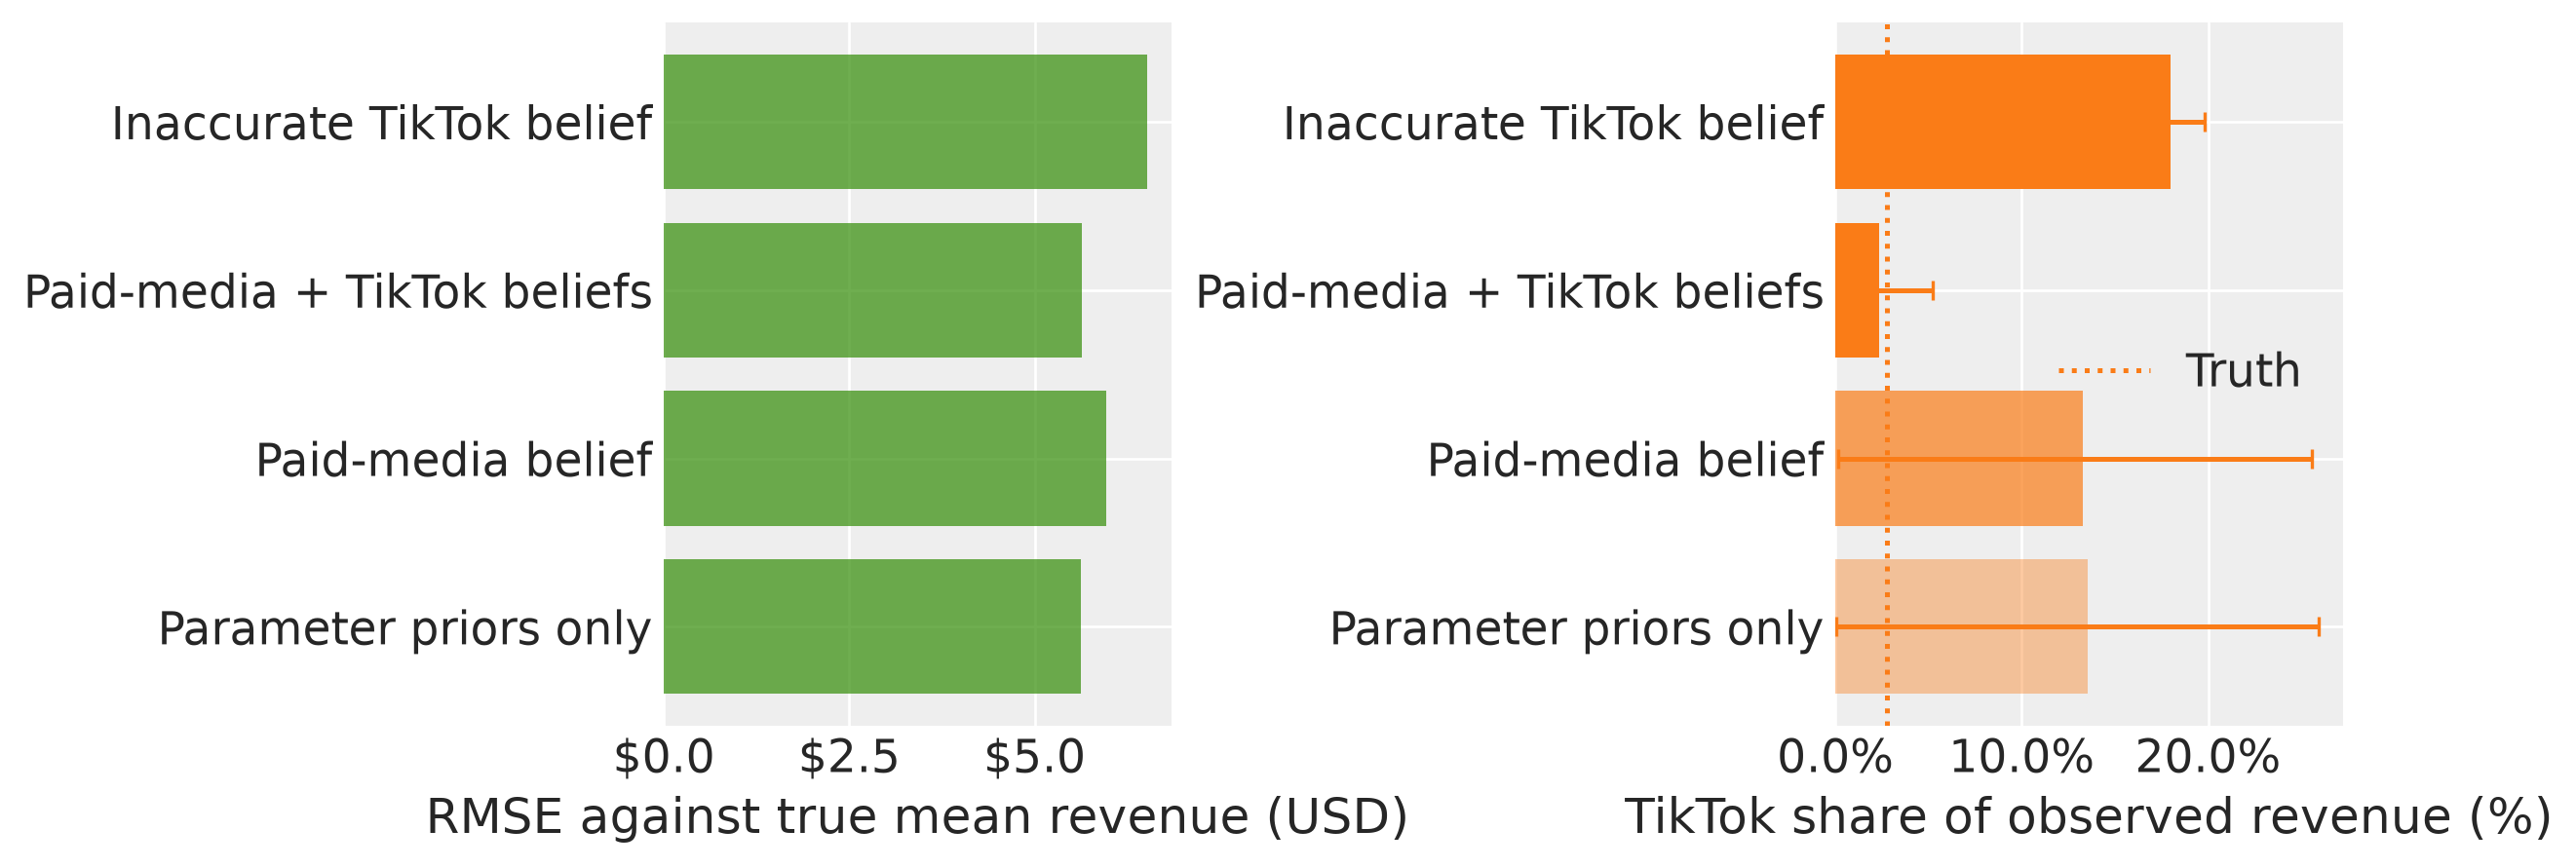

In [25]:
errors = {
    label: float(
        np.sqrt(
            np.mean(
                (mean_revenue(model.idata).mean(("chain", "draw")).values - true_mean)
                ** 2
            )
        )
    )
    for label, model in models.items()
}
fig, axes = plt.subplots(1, 2, figsize=(FIG_WIDTH, FIG_HEIGHT))
labels = list(models)
axes[0].barh(labels, [errors[k] for k in labels], color=MEDIA, alpha=0.7)
axes[0].set(xlabel="RMSE against true mean revenue (USD)")
axes[0].xaxis.set_major_formatter(StrMethodFormatter("${x:,.1f}"))
for i, label in enumerate(labels):
    draws = posterior_shares[label].tiktok
    bounds = np.asarray(az.hdi(draws, prob=0.94, dim=["chain", "draw"]))
    mean = float(draws.mean())
    axes[1].barh(i, mean, color=TIKTOK, alpha=STYLES[label][0])
    axes[1].errorbar(
        mean, i, xerr=[[mean - bounds[0]], [bounds[1] - mean]], color=TIKTOK, capsize=3
    )
axes[1].set(
    yticks=range(len(labels)),
    yticklabels=labels,
    xlabel="TikTok share of observed revenue (%)",
)
axes[1].axvline(true_shares["tiktok"], color=TIKTOK, linestyle=":", label="Truth")
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].legend()
plt.show()

**Caption:** Revenue error against the known noise-free mean, and TikTok posterior mean shares with 94% HDIs. The dotted line marks TikTok's true share.

In [26]:
display(
    Markdown(
        f"The inaccurate factor gives TikTok a posterior mean share of "
        f"{float(posterior_shares['Inaccurate TikTok belief'].tiktok.mean()):.1%}, "
        f"against truth {true_shares['tiktok']:.1%}. "
        f"True-mean revenue RMSE is ${errors['Parameter priors only']:.2f} with parameter priors only and "
        f"${errors['Inaccurate TikTok belief']:.2f} with the inaccurate belief. "
        "Revenue accuracy and channel-allocation accuracy answer different questions."
    )
)

The inaccurate factor gives TikTok a posterior mean share of 18.0%, against truth 2.8%. True-mean revenue RMSE is $5.63 with parameter priors only and $6.52 with the inaccurate belief. Revenue accuracy and channel-allocation accuracy answer different questions.

### Check the computations

MCMC diagnostics apply to the effective-prior runs as well as the posterior fits. The following checks summarize all parameters used in the example.

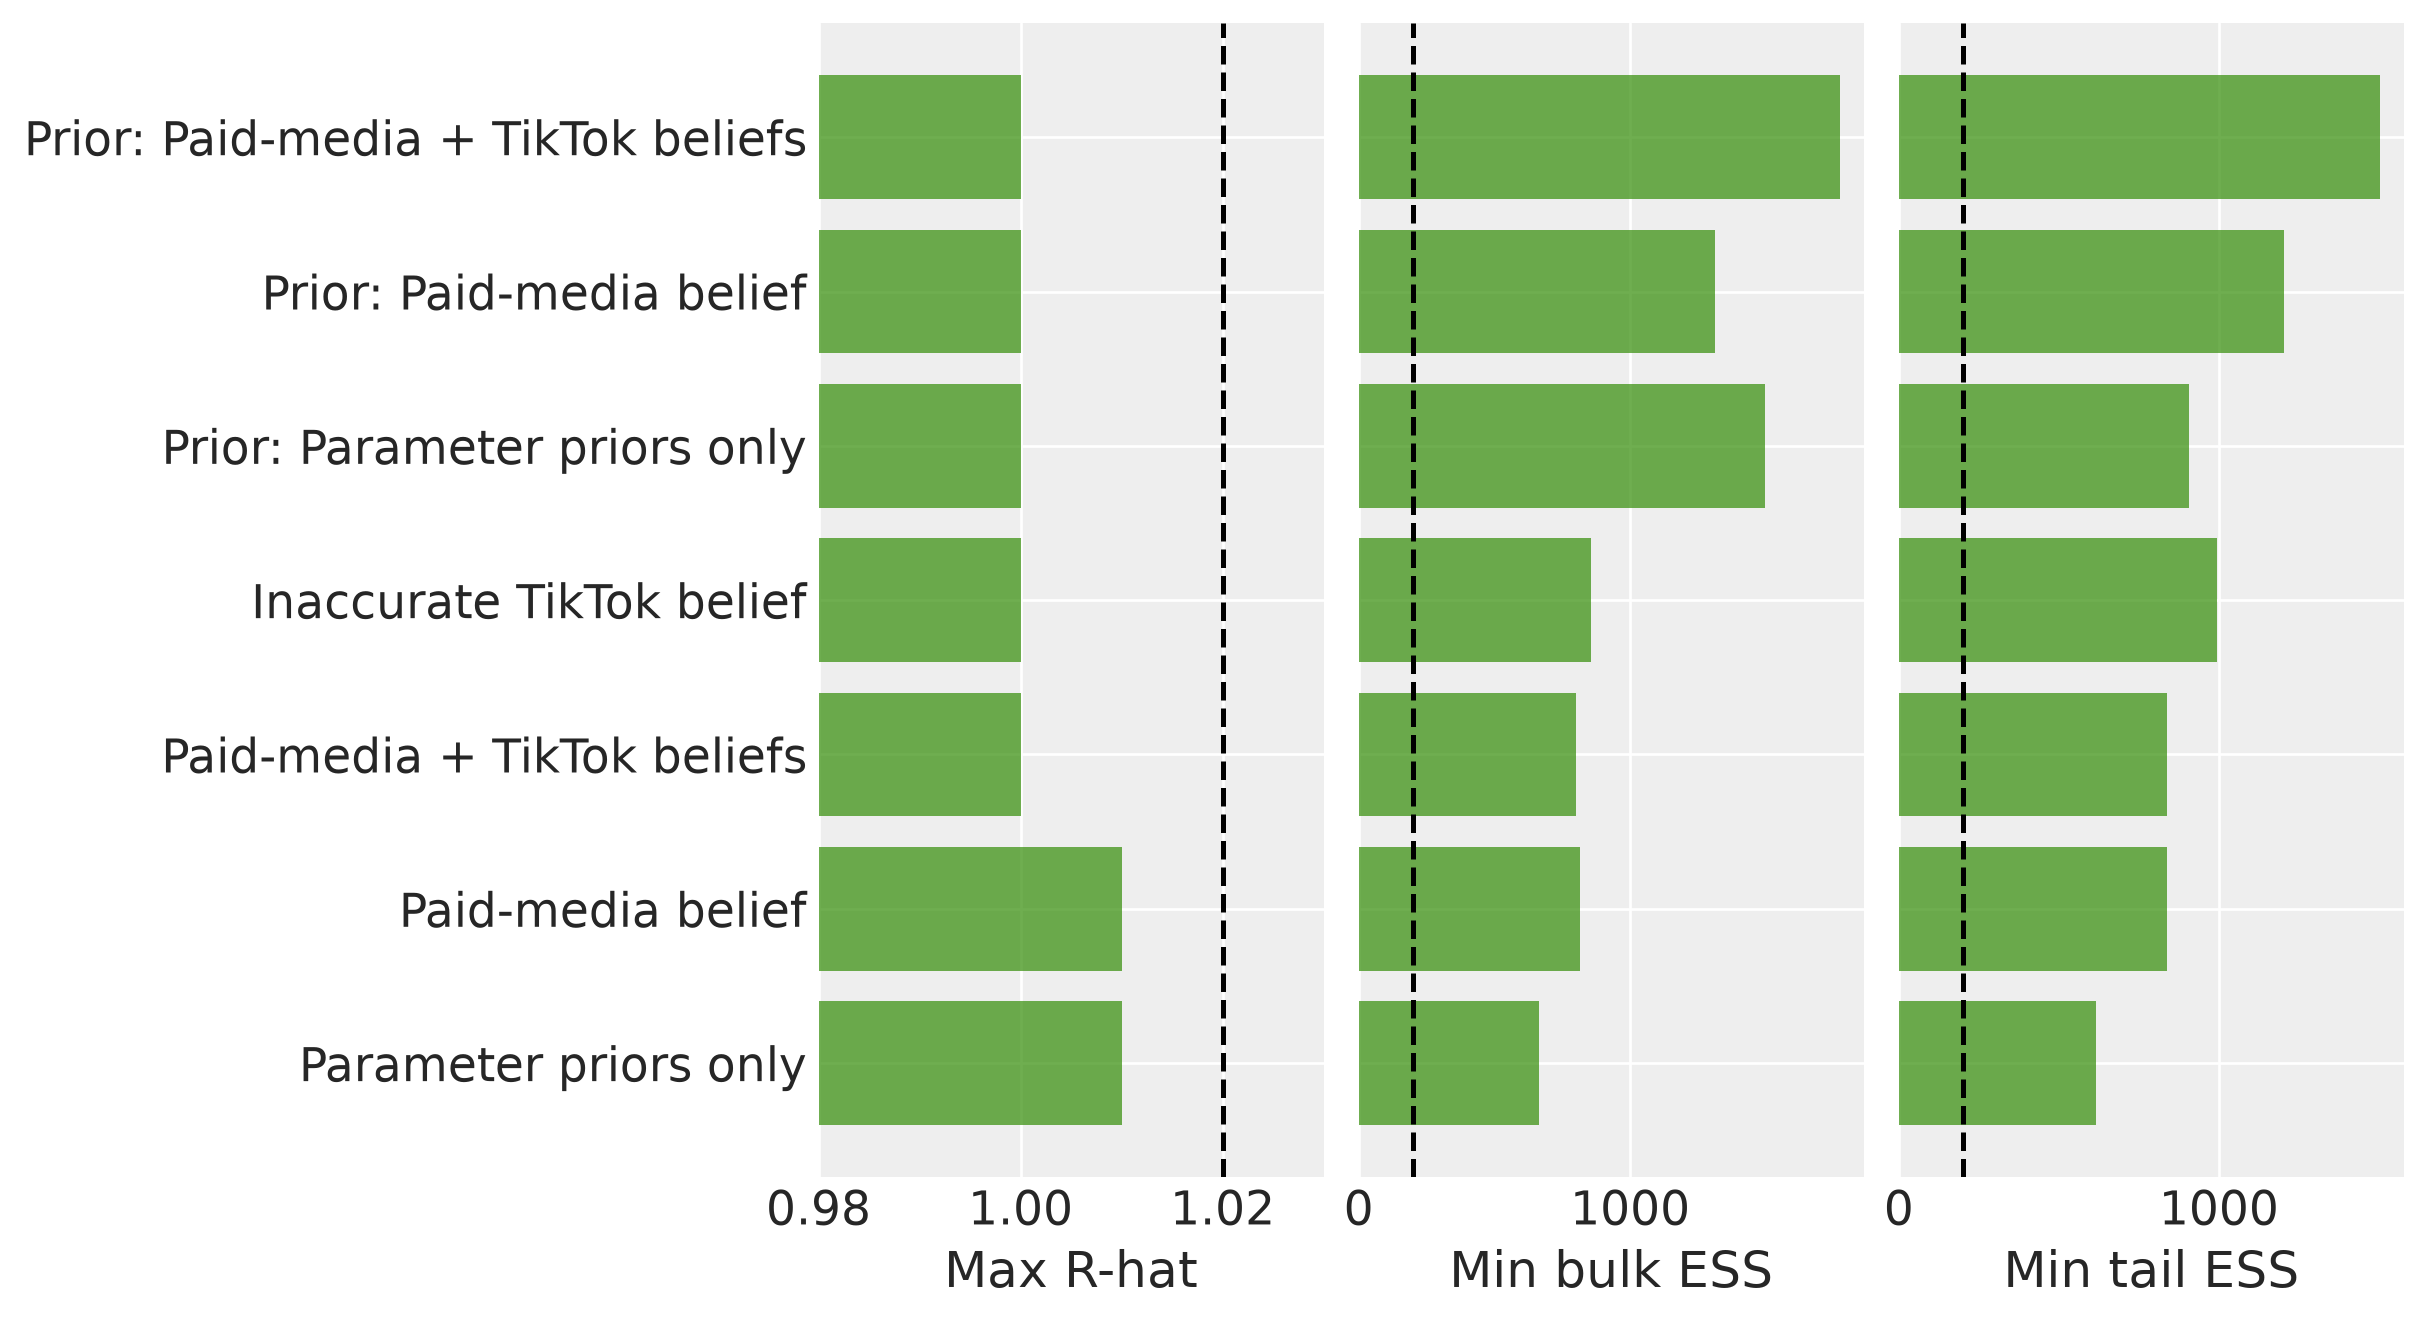

Total divergences: 0.

In [27]:
diagnostics = []
parameters = [
    "intercept_contribution",
    "adstock_alpha",
    "saturation_lam",
    "saturation_beta",
    "y_sigma",
]
runs = [(k, v.idata, "posterior", "sample_stats") for k, v in models.items()]
runs += [
    (f"Prior: {k}", v, "prior", "sample_stats_prior")
    for k, v in effective_priors.items()
]
for label, idata, group, stats_group in runs:
    summary = az.summary(idata[group].dataset, var_names=parameters, kind="diagnostics")
    diagnostics.append(
        {
            "Run": label,
            "Max R-hat": float(summary.r_hat.max()),
            "Min bulk ESS": float(summary.ess_bulk.min()),
            "Min tail ESS": float(summary.ess_tail.min()),
            "Divergences": int(idata[stats_group].diverging.sum()),
        }
    )
diagnostics = pd.DataFrame(diagnostics).set_index("Run")
fig, axes = plt.subplots(1, 3, figsize=(FIG_WIDTH, FIG_HEIGHT * 1.5), sharey=True)
for ax, column, limit in zip(
    axes, ["Max R-hat", "Min bulk ESS", "Min tail ESS"], [1.02, 200, 200], strict=True
):
    ax.barh(diagnostics.index, diagnostics[column], color=MEDIA, alpha=0.7)
    ax.axvline(limit, color="black", linestyle="--")
    ax.set(xlabel=column)
axes[0].set_xlim(0.98, max(1.03, diagnostics["Max R-hat"].max() + 0.005))
plt.show()
display(Markdown(f"Total divergences: {diagnostics.Divergences.sum()}."))
assert (diagnostics["Max R-hat"] < 1.02).all()  # noqa: S101
assert (diagnostics["Min bulk ESS"] > 200).all()  # noqa: S101
assert (diagnostics["Min tail ESS"] > 200).all()  # noqa: S101
assert (diagnostics.Divergences == 0).all()  # noqa: S101

**Caption:** Maximum R-hat and minimum bulk/tail effective sample sizes by run. Dashed lines mark the example's diagnostic thresholds.

## Use this with your own model

Build the MMM, add named factors for the channel totals or shares your team can judge, and inspect effective-prior revenue and ROAS before fitting. Compare the fitted breakdown with and without those judgments, and try a plausible alternative belief to assess sensitivity.

This example's small-channel assumption supplies much of its allocation information. In practice, record the business basis for that assumption and revisit it when the historical period changes. For experimental evidence, see the separate [lift-test calibration workflow](mmm_lift_test.ipynb).

API reference: {meth}`~pymc_marketing.mmm.mmm.MMM.add_contribution_factor` and {meth}`~pymc_marketing.mmm.mmm.MMM.sample_effective_prior`.

In [28]:
%load_ext watermark
%watermark -n -u -v -iv -w -p pymc_marketing,pymc,pytensor,pymc_extras,arviz,numpy,pandas,xarray,scipy,matplotlib

Last updated: Tue, 20 Oct 2026

Python implementation: CPython
Python version       : 3.12.12
IPython version      : 9.17.1

pymc_marketing: 1.2.0
pymc          : 6.3.2
pytensor      : 3.3.2
pymc_extras   : 0.15.1
arviz         : 1.2.0
numpy         : 2.4.6
pandas        : 3.0.5
xarray        : 2026.4.0
scipy         : 1.18.1
matplotlib    : 3.11.1

IPython       : 9.17.1
arviz         : 1.2.0
graphviz      : 0.21
matplotlib    : 3.11.1
numpy         : 2.4.6
pandas        : 3.0.5
pymc          : 6.3.2
pymc_extras   : 0.15.1
pymc_marketing: 1.2.0
pytensor      : 3.3.2
scipy         : 1.18.1
seaborn       : 0.13.2
xarray        : 2026.4.0

Watermark: 2.6.0

